<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Graphitic-Domain-Biochar-Machine-Learning/blob/main/Final_Note_3_Explainable_Prediction_of_Raman_ID_IG_from_FTIR_Spectra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import warnings
warnings.filterwarnings("ignore")

!pip install catboost

# ==========================================================
# PART 1. Import Libraries
# ==========================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    explained_variance_score
)

# Linear Models
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression

# Non-linear Models
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

from catboost import CatBoostRegressor

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 147.1 MB/s  0:00:00


In [3]:
# ==========================================================
# PART 2. Load Dataset
# ==========================================================

df = pd.read_excel("Data Collection of Biochar ML.xlsx")

print(df.shape)

df.head()

(486, 6860)


,sample_id,biomass,temp,replicate,y_idig,peak_OH,peak_CC_1600,peak_CO_1700,peak_CO_1050,peak_CH_2920,...,ftir_3995.951,ftir_3996.434,ftir_3996.916,ftir_3997.398,ftir_3997.88,ftir_3998.362,ftir_3998.844,ftir_3999.326,ftir_3999.809,ftir_4000.291
0,200_1,Sugar-apple Seed,200,1,0.886520,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000615,0.000544,0.000470,0.000395,0.000319,0.000241,0.000161,0.000080,-0.000003,-0.000088
1,200_1,Sugar-apple Seed,200,2,0.851280,5.510390,2.693430,16.649050,1.466970,0.253510,...,0.000661,0.000576,0.000488,0.000399,0.000308,0.000214,0.000119,0.000021,-0.000078,-0.000180
2,200_2,Sugar-apple Seed,200,3,0.892340,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000093,0.000054,0.000015,-0.000025,-0.000066,-0.000107,-0.000149,-0.000191,-0.000234,-0.000278
3,200_4,Sugar-apple Seed,200,4,0.882533,6.206852,2.474513,14.526912,1.349543,0.204830,...,0.000569,0.000541,0.000480,0.000375,0.000321,0.000243,0.000160,0.000080,-0.000003,-0.000091
4,200_5,Sugar-apple Seed,200,5,0.885443,5.865407,2.514734,14.461602,1.446849,0.209381,...,0.000609,0.000572,0.000477,0.000420,0.000319,0.000245,0.000161,0.000083,-0.000003,-0.000088


In [4]:
# ==========================================================
# PART 3. Automatic Feature Detection
# ==========================================================

# ---------- FTIR ----------
ftir_cols = [col for col in df.columns if col.startswith('ftir_')]

# ---------- Metadata ----------

metadata_cols = []

# Corrected: Use actual column names 'temp' and 'biomass' found in df
possible_metadata = [
    "biomass", # Corrected from "Biomass"
    "temp",      # Corrected from "Temperature"
    "Classification" # Including Classification as it's a non-numeric metadata column
]

for c in possible_metadata:

    if c in df.columns:

        metadata_cols.append(c)

# ---------- Target ----------

target = "y_idig"

# ---------- Peak Features ----------

peak_cols = []

for col in df.columns:

    if col in ftir_cols:
        continue

    # Exclude metadata columns from peak_cols
    if col in metadata_cols:
        continue

    if col == target:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):

        peak_cols.append(col)

print("="*60)
print("FTIR :",len(ftir_cols))
print("Peak :",len(peak_cols))
print("Metadata :",metadata_cols)
print("="*60)

FTIR : 6847
Peak : 9
Metadata : ['biomass', 'temp']


In [5]:
# ==========================================================
# PART 4. Feature Set Construction
# ==========================================================

feature_sets = {

    "Peak": peak_cols,

    "FTIR": ftir_cols,

    "Peak+Temp":
        peak_cols + ["temp"], # Corrected from "Temperature"

    "Peak+Biomass":
        peak_cols + ["biomass"], # Corrected from "Biomass"

    "FTIR+Temp":
        ftir_cols + ["temp"], # Corrected from "Temperature"

    "FTIR+Biomass":
        ftir_cols + ["biomass"], # Corrected from "Biomass"

    "Peak+Temp+Biomass":
        peak_cols + ["temp", "biomass"], # Corrected to use peak_cols and correct lowercase names

    "FTIR+Temp+Biomass":
        ftir_cols + ["temp", "biomass"], # Corrected to use correct lowercase names

    "All":
        list(set(ftir_cols + peak_cols + metadata_cols)) # Use set to handle potential duplicates and ensure all correct metadata are included

}

for k,v in feature_sets.items():

    print(k,":",len(v))

Peak : 9
FTIR : 6847
Peak+Temp : 10
Peak+Biomass : 10
FTIR+Temp : 6848
FTIR+Biomass : 6848
Peak+Temp+Biomass : 11
FTIR+Temp+Biomass : 6849
All : 6858


In [6]:
# ==========================================================
# PART 5. Build Preprocessing Pipeline
# ==========================================================

from sklearn.compose import make_column_selector

def build_preprocessor(feature_columns):

    numeric_features = []

    categorical_features = []

    for col in feature_columns:

        if pd.api.types.is_numeric_dtype(df[col]):

            numeric_features.append(col)

        else:

            categorical_features.append(col)

    numeric_transformer = Pipeline([

        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler())

    ])

    categorical_transformer = Pipeline([

        ("imputer", SimpleImputer(strategy="most_frequent")),

        ("encoder", OneHotEncoder(handle_unknown="ignore"))

    ])

    preprocessor = ColumnTransformer(

        transformers=[

            ("num",
             numeric_transformer,
             numeric_features),

            ("cat",
             categorical_transformer,
             categorical_features)

        ]

    )

    return preprocessor

In [7]:
# ==========================================================
# PART 6. Candidate Models
# ==========================================================

models = {

    "Ridge":
        Ridge(random_state=RANDOM_STATE),

     "PLSR":
        PLSRegression(n_components=2),

    "Random Forest":
        RandomForestRegressor(
            random_state=RANDOM_STATE
        ),

    "XGBoost":
        XGBRegressor(
            random_state=RANDOM_STATE,
            verbosity=0
        ),
    "CatBoost":
        CatBoostRegressor(
            random_state=RANDOM_STATE,
            verbose=False
        )

}

print(models.keys())

dict_keys(['Ridge', 'PLSR', 'Random Forest', 'XGBoost', 'CatBoost'])


In [8]:
# ==========================================================
# PART 7. Evaluation Function
# ==========================================================

from sklearn.base import clone

def evaluate_model(model,
                   feature_columns):

    X = df[feature_columns]

    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(

        X,

        y,

        test_size=0.20,

        random_state=RANDOM_STATE

    )

    preprocessor = build_preprocessor(
        feature_columns
    )

    pipe = Pipeline([

        ("prep",preprocessor),

        ("model",clone(model))

    ])

    pipe.fit(
        X_train,
        y_train
    )

    pred_train = pipe.predict(X_train)

    pred_test = pipe.predict(X_test)

    result = {

        "Train_R2":
            r2_score(
                y_train,
                pred_train
            ),

        "Test_R2":
            r2_score(
                y_test,
                pred_test
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_test,
                    pred_test
                )
            ),

        "MAE":
            mean_absolute_error(
                y_test,
                pred_test
            ),

        "MAPE":
            mean_absolute_percentage_error(
                y_test,
                pred_test
            ),

        "ExplainedVariance":
            explained_variance_score(
                y_test,
                pred_test
            )

    }

    return result

In [9]:
# ==========================================================
# PART 8. Benchmark All Models
# ==========================================================

target = "y_idig"

results = []

# Removed the temporary fix block as feature_sets will now be correctly defined

for feature_name, feature_columns in feature_sets.items():

    print("="*70)
    print(feature_name)
    print("="*70)

    # Add a check to prevent running models with empty feature sets
    if not feature_columns:
        print(f"Skipping {feature_name} as it has no features.")
        continue

    for model_name, model in models.items():

        print(f"Running {model_name}...")

        score = evaluate_model(
            model,
            feature_columns
        )

        score["Feature_Set"] = feature_name
        score["Model"] = model_name

        results.append(score)

results = pd.DataFrame(results)

results = results[
    [
        "Feature_Set",
        "Model",
        "Train_R2",
        "Test_R2",
        "RMSE",
        "MAE",
        "MAPE",
        "ExplainedVariance"
    ]
]

results.sort_values(
    by="Test_R2",
    ascending=False,
    inplace=True
)

results.reset_index(drop=True,
                    inplace=True)

results

Peak
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
FTIR
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
Peak+Temp
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
Peak+Biomass
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
FTIR+Temp
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
FTIR+Biomass
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
Peak+Temp+Biomass
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
FTIR+Temp+Biomass
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...
All
Running Ridge...
Running PLSR...
Running Random Forest...
Running XGBoost...
Running CatBoost...


,Feature_Set,Model,Train_R2,Test_R2,RMSE,MAE,MAPE,ExplainedVariance
0,Peak+Temp+Biomass,Random Forest,0.991486,0.957991,0.040925,0.025909,0.024303,0.958522
1,Peak+Biomass,Random Forest,0.990757,0.955546,0.042099,0.026443,0.024904,0.956121
2,Peak+Temp,Random Forest,0.988817,0.951993,0.043749,0.028670,0.026632,0.952395
3,Peak,Random Forest,0.988399,0.950788,0.044295,0.028628,0.026631,0.951141
4,Peak+Biomass,XGBoost,0.999901,0.950078,0.044613,0.029333,0.026967,0.950241
5,Peak,XGBoost,0.999908,0.948914,0.045130,0.028950,0.026634,0.949002
6,Peak+Temp,CatBoost,0.996315,0.943343,0.047527,0.030298,0.026813,0.943376
7,Peak+Temp+Biomass,CatBoost,0.997115,0.940854,0.048560,0.030187,0.026517,0.940880
8,FTIR+Temp+Biomass,XGBoost,0.999987,0.938348,0.049578,0.031138,0.028531,0.938378
9,FTIR+Temp,XGBoost,0.999983,0.935658,0.050648,0.032023,0.029272,0.935713


In [10]:
# ==========================================================
# PART 9. Model Ranking
# ==========================================================

results.style.background_gradient(
    subset=["Test_R2"],
    cmap="Greens"
).background_gradient(
    subset=["RMSE"],
    cmap="Reds_r"
)

,Feature_Set,Model,Train_R2,Test_R2,RMSE,MAE,MAPE,ExplainedVariance
0,Peak+Temp+Biomass,Random Forest,0.991486,0.957991,0.040925,0.025909,0.024303,0.958522
1,Peak+Biomass,Random Forest,0.990757,0.955546,0.042099,0.026443,0.024904,0.956121
2,Peak+Temp,Random Forest,0.988817,0.951993,0.043749,0.028670,0.026632,0.952395
3,Peak,Random Forest,0.988399,0.950788,0.044295,0.028628,0.026631,0.951141
4,Peak+Biomass,XGBoost,0.999901,0.950078,0.044613,0.029333,0.026967,0.950241
5,Peak,XGBoost,0.999908,0.948914,0.045130,0.028950,0.026634,0.949002
6,Peak+Temp,CatBoost,0.996315,0.943343,0.047527,0.030298,0.026813,0.943376
7,Peak+Temp+Biomass,CatBoost,0.997115,0.940854,0.048560,0.030187,0.026517,0.940880
8,FTIR+Temp+Biomass,XGBoost,0.999987,0.938348,0.049578,0.031138,0.028531,0.938378
9,FTIR+Temp,XGBoost,0.999983,0.935658,0.050648,0.032023,0.029272,0.935713


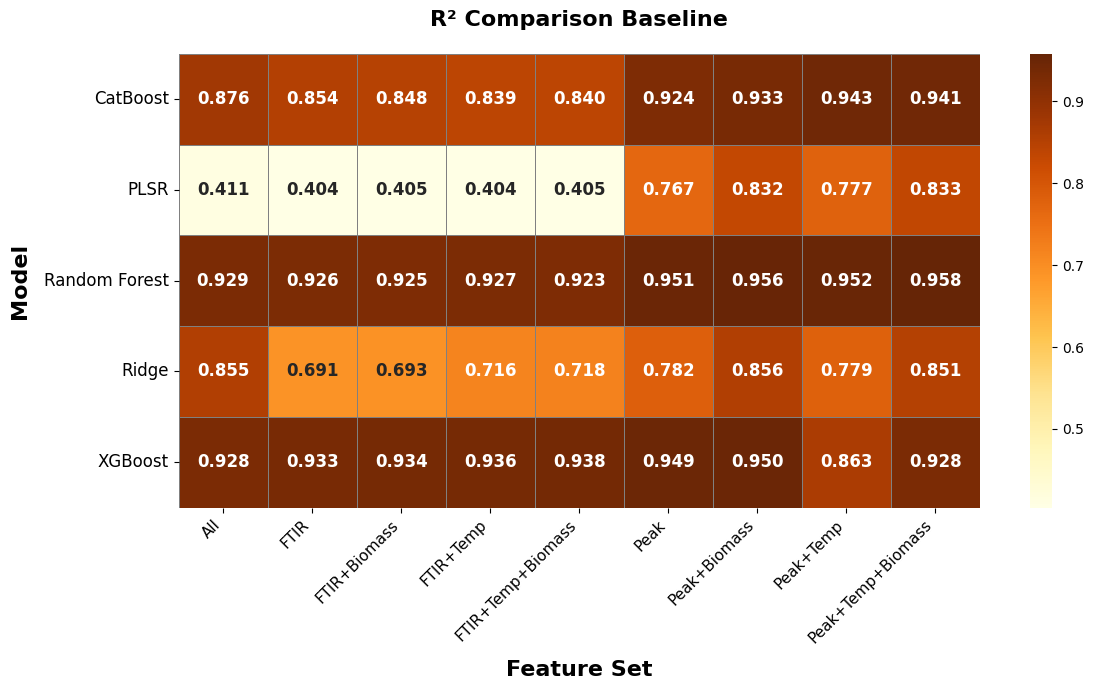

In [11]:
# ==========================================================
# PART 10. Performance Heatmap (Maple Theme) - Revised
# ==========================================================

pivot_r2 = results.pivot_table(
    index="Model",
    columns="Feature_Set",
    values="Test_R2"
)

plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_r2,
    annot=True,
    cmap="YlOrBr",  # Warm Maple tones
    fmt=".3f",
    annot_kws={"size": 12, "weight": "bold"},
    linewidths=0.5,
    linecolor='gray'
)

plt.title("R² Comparison Baseline", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Feature Set", fontsize=16, fontweight='bold', labelpad=10)
plt.ylabel("Model", fontsize=16, fontweight='bold', labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

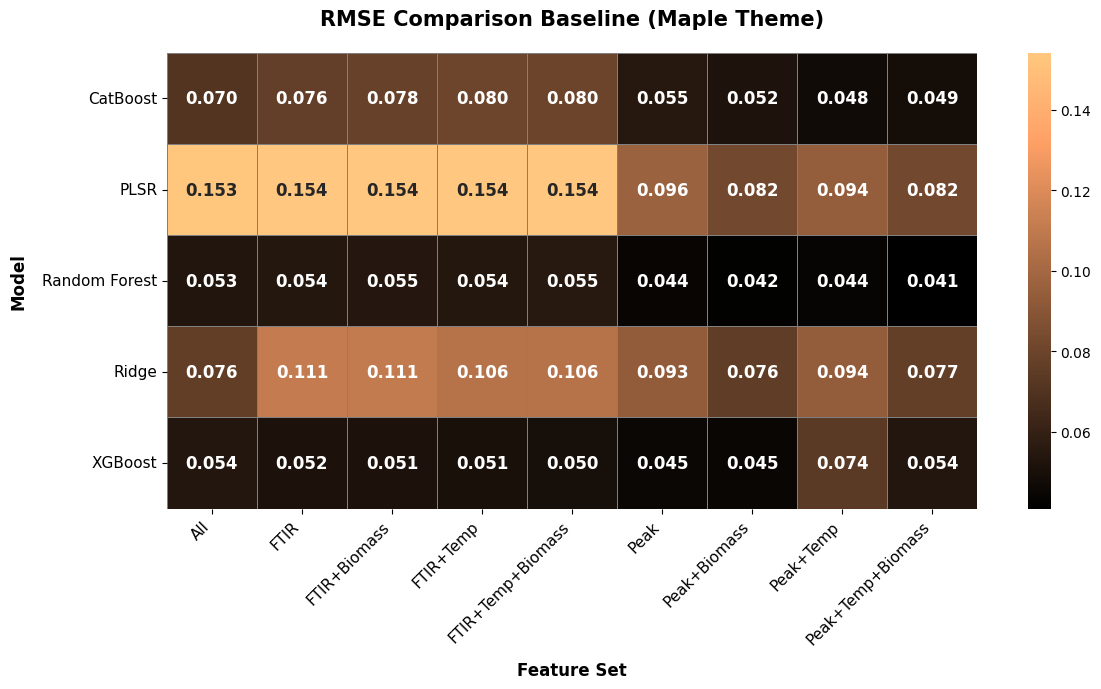

In [12]:
# ==========================================================
# PART 11. RMSE Heatmap (Maple Theme) - Revised
# ==========================================================

pivot_rmse = results.pivot_table(
    index="Model",
    columns="Feature_Set",
    values="RMSE"
)

plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_rmse,
    annot=True,
    cmap="copper",  # Earthy autumn maple tones
    fmt=".3f",
    annot_kws={"size": 12, "weight": "bold"},
    linewidths=0.5,
    linecolor='gray'
)

plt.title("RMSE Comparison Baseline (Maple Theme)", fontsize=15, fontweight='bold', pad=20)
plt.xlabel("Feature Set", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Model", fontsize=12, fontweight='bold', labelpad=10)

plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()

In [13]:
# ==========================================================
# PART 12. Feature Importance (Feature Set)
# ==========================================================

feature_summary = (

    results

    .groupby("Feature_Set")

    [["Test_R2","RMSE"]]

    .mean()

    .sort_values(

        "Test_R2",

        ascending=False

    )

)

feature_summary

,Test_R2,RMSE
Feature_Set,,
Peak+Biomass,0.905431,0.059171
Peak+Temp+Biomass,0.902036,0.060382
Peak,0.874662,0.066781
Peak+Temp,0.863104,0.070613
All,0.799866,0.081253
FTIR+Temp+Biomass,0.765040,0.088930
FTIR+Temp,0.764526,0.089030
FTIR,0.761731,0.089435
FTIR+Biomass,0.760989,0.089674


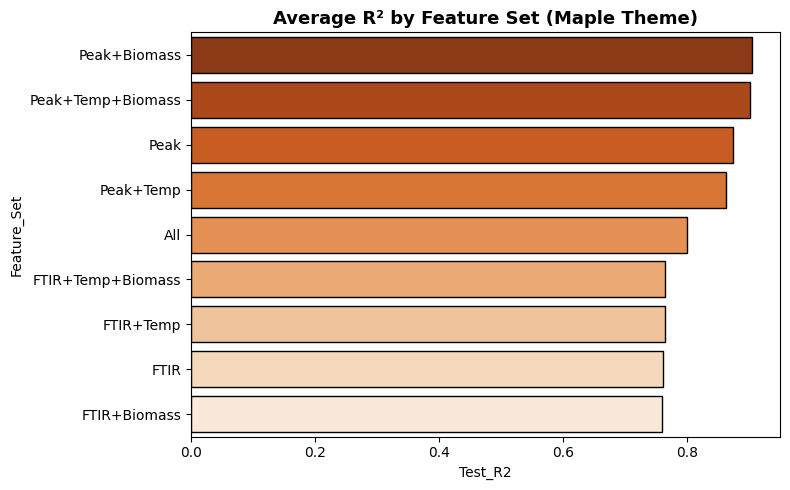

In [14]:
# ==========================================================
# Average R2 by Feature Set (Maple Theme)
# ==========================================================
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_summary.reset_index(),
    x="Test_R2",
    y="Feature_Set",
    palette="Oranges_r",  # Golden maple leaf gradient
    edgecolor="black"
)
plt.title("Average R² by Feature Set (Maple Theme)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [15]:
# ==========================================================
# PART 13. Model Comparison
# ==========================================================

model_summary = (

    results

    .groupby("Model")

    [["Test_R2","RMSE"]]

    .mean()

    .sort_values(

        "Test_R2",

        ascending=False

    )

)

model_summary

,Test_R2,RMSE
Model,,
Random Forest,0.938583,0.049143
XGBoost,0.928903,0.052625
CatBoost,0.888807,0.065214
Ridge,0.771318,0.094433
PLSR,0.582047,0.124846


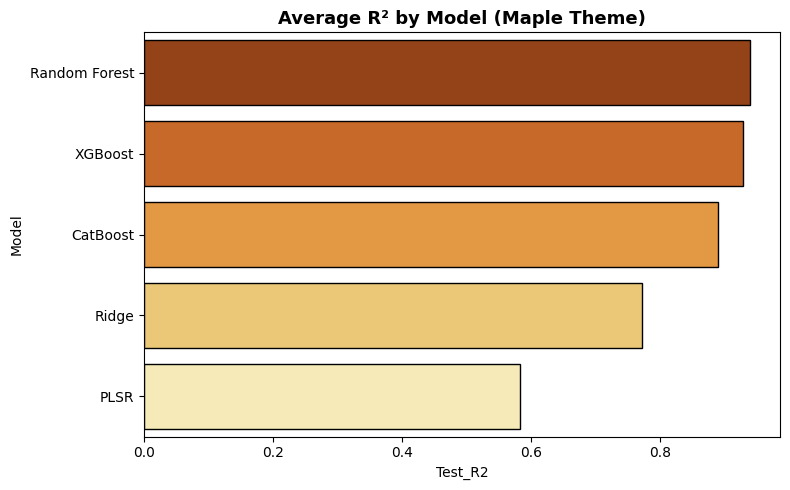

In [16]:
# ==========================================================
# Average R2 by Model (Maple Theme)
# ==========================================================
plt.figure(figsize=(8,5))

sns.barplot(
    data=model_summary.reset_index(),
    x="Test_R2",
    y="Model",
    palette="YlOrBr_r",  # Amber-maple tones
    edgecolor="black"
)
plt.title("Average R² by Model (Maple Theme)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# ==========================================================
# PART 14. Top 10 Configurations
# ==========================================================

top10 = results.head(11)

top10

,Feature_Set,Model,Train_R2,Test_R2,RMSE,MAE,MAPE,ExplainedVariance
0,Peak+Temp+Biomass,Random Forest,0.991486,0.957991,0.040925,0.025909,0.024303,0.958522
1,Peak+Biomass,Random Forest,0.990757,0.955546,0.042099,0.026443,0.024904,0.956121
2,Peak+Temp,Random Forest,0.988817,0.951993,0.043749,0.028670,0.026632,0.952395
3,Peak,Random Forest,0.988399,0.950788,0.044295,0.028628,0.026631,0.951141
4,Peak+Biomass,XGBoost,0.999901,0.950078,0.044613,0.029333,0.026967,0.950241
5,Peak,XGBoost,0.999908,0.948914,0.045130,0.028950,0.026634,0.949002
6,Peak+Temp,CatBoost,0.996315,0.943343,0.047527,0.030298,0.026813,0.943376
7,Peak+Temp+Biomass,CatBoost,0.997115,0.940854,0.048560,0.030187,0.026517,0.940880
8,FTIR+Temp+Biomass,XGBoost,0.999987,0.938348,0.049578,0.031138,0.028531,0.938378
9,FTIR+Temp,XGBoost,0.999983,0.935658,0.050648,0.032023,0.029272,0.935713


```markdown
# ==========================================================
# PART 14A. OPTUNA HYPERPARAMETER TUNING (Peak+Temp+Biomass)
# ==========================================================
In this section, we perform rigorous hyperparameter optimization using **Optuna** for all candidate models (`Ridge`, `PLSR`, `Random Forest`, `XGBoost`, `CatBoost`) specifically on the **`Peak+Temp+Biomass`** feature set.

To ensure robust, stable, and reliable evaluations, we implement a **`StratifiedKFold`** splitting strategy based on the `biomass` category in each cross-validation fold. This prevents any single group from dominating a fold and yields highly generalized hyperparameter configurations.
```

In [18]:
!pip install optuna

import optuna
import logging
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Mematikan log verbose dari optuna agar output tetap bersih
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Mempersiapkan data untuk set fitur Peak+Temp+Biomass
ptb_features = feature_sets["Peak+Temp+Biomass"]
X_ptb = df[ptb_features]
y_ptb = df[target]
preprocessor_ptb = build_preprocessor(ptb_features)

# Menggunakan StratifiedKFold berdasarkan jenis biomass untuk validasi yang stabil
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(stratified_cv.split(X_ptb, df["biomass"]))

# Dictionary untuk menampung parameter terbaik
best_tuned_params = {}


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [19]:
# 1. Tuning Ridge
def objective_ridge(trial):
    alpha = trial.suggest_float("alpha", 1e-3, 100.0, log=True)
    model = Ridge(alpha=alpha, random_state=RANDOM_STATE)
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    score = cross_val_score(pipe, X_ptb, y_ptb, cv=cv_splits, scoring="r2", n_jobs=-1)
    return score.mean()

study_ridge = optuna.create_study(direction="maximize")
study_ridge.optimize(objective_ridge, n_trials=15)
best_tuned_params["Ridge"] = study_ridge.best_params
print(f"[Optuna] Ridge Best R²: {study_ridge.best_value:.4f} | Params: {study_ridge.best_params}")

[Optuna] Ridge Best R²: 0.7118 | Params: {'alpha': 2.2798826272240134}


In [20]:
# 2. Tuning PLSR
def objective_plsr(trial):
    n_components = trial.suggest_int("n_components", 1, min(len(ptb_features), 8))
    model = PLSRegression(n_components=n_components)
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    score = cross_val_score(pipe, X_ptb, y_ptb, cv=cv_splits, scoring="r2", n_jobs=-1)
    return score.mean()

study_plsr = optuna.create_study(direction="maximize")
study_plsr.optimize(objective_plsr, n_trials=8)
best_tuned_params["PLSR"] = study_plsr.best_params
print(f"[Optuna] PLSR Best R²: {study_plsr.best_value:.4f} | Params: {study_plsr.best_params}")

[Optuna] PLSR Best R²: 0.7123 | Params: {'n_components': 8}


In [21]:
# 3. Tuning Random Forest
def objective_rf_ptb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 5, 25),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "random_state": RANDOM_STATE
    }
    model = RandomForestRegressor(**params)
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    score = cross_val_score(pipe, X_ptb, y_ptb, cv=cv_splits, scoring="r2", n_jobs=-1)
    return score.mean()

study_rf_ptb = optuna.create_study(direction="maximize")
study_rf_ptb.optimize(objective_rf_ptb, n_trials=15)
best_tuned_params["Random Forest"] = study_rf_ptb.best_params
print(f"[Optuna] Random Forest Best R²: {study_rf_ptb.best_value:.4f} | Params: {study_rf_ptb.best_params}")

[Optuna] Random Forest Best R²: 0.9309 | Params: {'n_estimators': 257, 'max_depth': 16, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


In [22]:
# 4. Tuning XGBoost
def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "random_state": RANDOM_STATE,
        "verbosity": 0
    }
    model = XGBRegressor(**params)
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    score = cross_val_score(pipe, X_ptb, y_ptb, cv=cv_splits, scoring="r2", n_jobs=-1)
    return score.mean()

study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(objective_xgb, n_trials=15)
best_tuned_params["XGBoost"] = study_xgb.best_params
print(f"[Optuna] XGBoost Best R²: {study_xgb.best_value:.4f} | Params: {study_xgb.best_params}")

[Optuna] XGBoost Best R²: 0.9415 | Params: {'n_estimators': 307, 'max_depth': 3, 'learning_rate': 0.11058611149448229, 'subsample': 0.7355131641575576, 'colsample_bytree': 0.7537366145034304}


In [23]:
# 5. Tuning CatBoost
def objective_cat(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 100, 500),
        "depth": trial.suggest_int("depth", 4, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "random_seed": RANDOM_STATE,
        "verbose": False
    }
    model = CatBoostRegressor(**params)
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    score = cross_val_score(pipe, X_ptb, y_ptb, cv=cv_splits, scoring="r2", n_jobs=-1)
    return score.mean()

study_cat = optuna.create_study(direction="maximize")
study_cat.optimize(objective_cat, n_trials=15)
best_tuned_params["CatBoost"] = study_cat.best_params
print(f"[Optuna] CatBoost Best R²: {study_cat.best_value:.4f} | Params: {study_cat.best_params}")

[Optuna] CatBoost Best R²: 0.9414 | Params: {'iterations': 397, 'depth': 6, 'learning_rate': 0.07885688786799129}


In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import cross_validate

# Inisialisasi list untuk menampung baris data
tuned_summary_data = []

# Definisikan model yang telah di-tuning menggunakan parameter terbaik dari Optuna
tuned_models = {
    "Ridge": Ridge(**best_tuned_params["Ridge"], random_state=RANDOM_STATE),
    "PLSR": PLSRegression(**best_tuned_params["PLSR"]),
    "Random Forest": RandomForestRegressor(**best_tuned_params["Random Forest"], random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(**best_tuned_params["XGBoost"], random_state=RANDOM_STATE, verbosity=0),
    "CatBoost": CatBoostRegressor(**best_tuned_params["CatBoost"], random_seed=RANDOM_STATE, verbose=False)
}

print("Calculating validation metrics for tuned models using Stratified K-Fold...")

for name, model in tuned_models.items():
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])

    # Melakukan cross-validate untuk mendapatkan metrik lengkap
    cv_results = cross_validate(
        pipe,
        X_ptb,
        y_ptb,
        cv=cv_splits,
        scoring={
            "r2": "r2",
            "neg_rmse": "neg_root_mean_squared_error",
            "neg_mae": "neg_mean_absolute_error",
            "neg_mape": "neg_mean_absolute_percentage_error"
        },
        n_jobs=-1
    )

    # Ambil nilai rata-rata dari setiap metrik
    mean_r2 = cv_results["test_r2"].mean()
    mean_rmse = -cv_results["test_neg_rmse"].mean()
    mean_mae = -cv_results["test_neg_mae"].mean()
    mean_mape = -cv_results["test_neg_mape"].mean()

    tuned_summary_data.append({
        "Model": name,
        "Best R²": round(mean_r2, 4),
        "RMSE": round(mean_rmse, 4),
        "MAE": round(mean_mae, 4),
        "MAPE": f"{mean_mape * 100:.2f}%",
        "Best Parameters": str(best_tuned_params[name])
    })

# Membuat DataFrame hasil
df_tuned_benchmark = pd.DataFrame(tuned_summary_data).sort_values(by="Best R²", ascending=False).reset_index(drop=True)
display(df_tuned_benchmark)

Calculating validation metrics for tuned models using Stratified K-Fold...


,Model,Best R²,RMSE,MAE,MAPE,Best Parameters
0,XGBoost,0.9415,0.0354,0.0237,2.21%,"{'n_estimators': 307, 'max_depth': 3, 'learnin..."
1,CatBoost,0.9414,0.0346,0.0227,2.11%,"{'iterations': 397, 'depth': 6, 'learning_rate..."
2,Random Forest,0.9309,0.0381,0.0248,2.28%,"{'n_estimators': 257, 'max_depth': 16, 'min_sa..."
3,PLSR,0.7123,0.0807,0.0612,5.72%,{'n_components': 8}
4,Ridge,0.7118,0.0806,0.0614,5.73%,{'alpha': 2.2798826272240134}


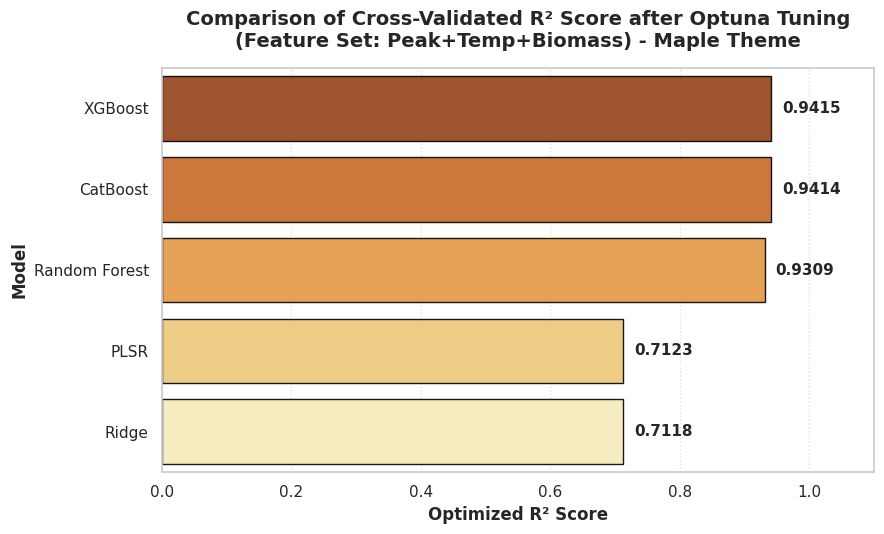

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5.5))

# Membuat plot batang untuk Best R2 setelah Tuning
sns.barplot(
    data=df_tuned_benchmark,
    x="Best R²",
    y="Model",
    palette="YlOrBr_r",  # Gradasi warna maple hangat
    edgecolor="black",
    alpha=0.9
)

# Menambahkan anotasi nilai di setiap batang
ax = plt.gca()
for p in ax.patches:
    if p.get_width() > 0:
        ax.annotate(f"{p.get_width():.4f}",
                    (p.get_width(), p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(8, 0),
                    textcoords='offset points',
                    fontsize=11, fontweight='bold')

plt.title("Comparison of Cross-Validated R² Score after Optuna Tuning\n(Feature Set: Peak+Temp+Biomass) - Maple Theme", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Optimized R² Score", fontsize=12, fontweight='bold')
plt.ylabel("Model", fontsize=12, fontweight='bold')
plt.xlim(0, 1.1)  # Memberikan ruang untuk label teks
plt.grid(True, linestyle=":", alpha=0.6, axis='x')

plt.tight_layout()
plt.show()

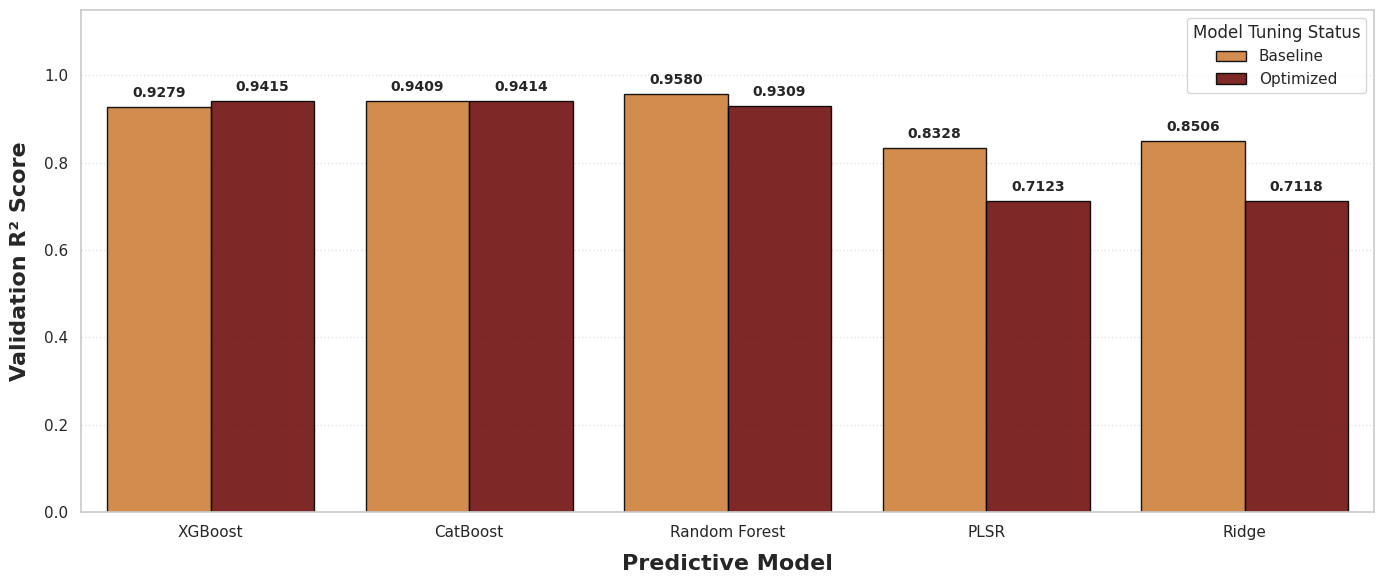

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ambil data Baseline (sebelum tuning) khusus untuk set fitur 'Peak+Temp+Biomass'
df_baseline_ptb = results[results["Feature_Set"] == "Peak+Temp+Biomass"][["Model", "Test_R2"]].copy()
df_baseline_ptb.rename(columns={"Test_R2": "R² Score"}, inplace=True)
df_baseline_ptb["Status"] = "Baseline"

# 2. Ambil data hasil Optimasi (setelah tuning dengan Optuna)
df_optimized_ptb = df_tuned_benchmark[["Model", "Best R²"]].copy()
df_optimized_ptb.rename(columns={"Best R²": "R² Score"}, inplace=True)
df_optimized_ptb["Status"] = "Optimized"

# 3. Gabungkan kedua DataFrame
df_comparison = pd.concat([df_baseline_ptb, df_optimized_ptb], ignore_index=True)

# Urutkan berdasarkan nilai R2 tertinggi pada status Optimized untuk estetika
model_order = df_optimized_ptb.sort_values(by="R² Score", ascending=False)["Model"].tolist()

# 4. Visualisasi
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Membuat plot batang kelompok
sns.barplot(
    data=df_comparison,
    x="Model",
    y="R² Score",
    hue="Status",
    order=model_order,
    palette=["#e67e22", "#800000"],  # Jingga hangat (Baseline) & Merah bata/Mahoni tua (Optimized)
    edgecolor="black",
    alpha=0.9
)

# Menambahkan label nilai di atas setiap batang
ax = plt.gca()
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.4f}",
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.xlabel("Predictive Model", fontsize=16, fontweight='bold', labelpad=10)
plt.ylabel("Validation R² Score", fontsize=16, fontweight='bold', labelpad=10)
plt.ylim(0, 1.15)  # Memberikan ruang untuk label anotasi angka
plt.legend(title="Model Tuning Status", fontsize=11, title_fontsize=12, loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6, axis='y')

plt.tight_layout()
plt.show()

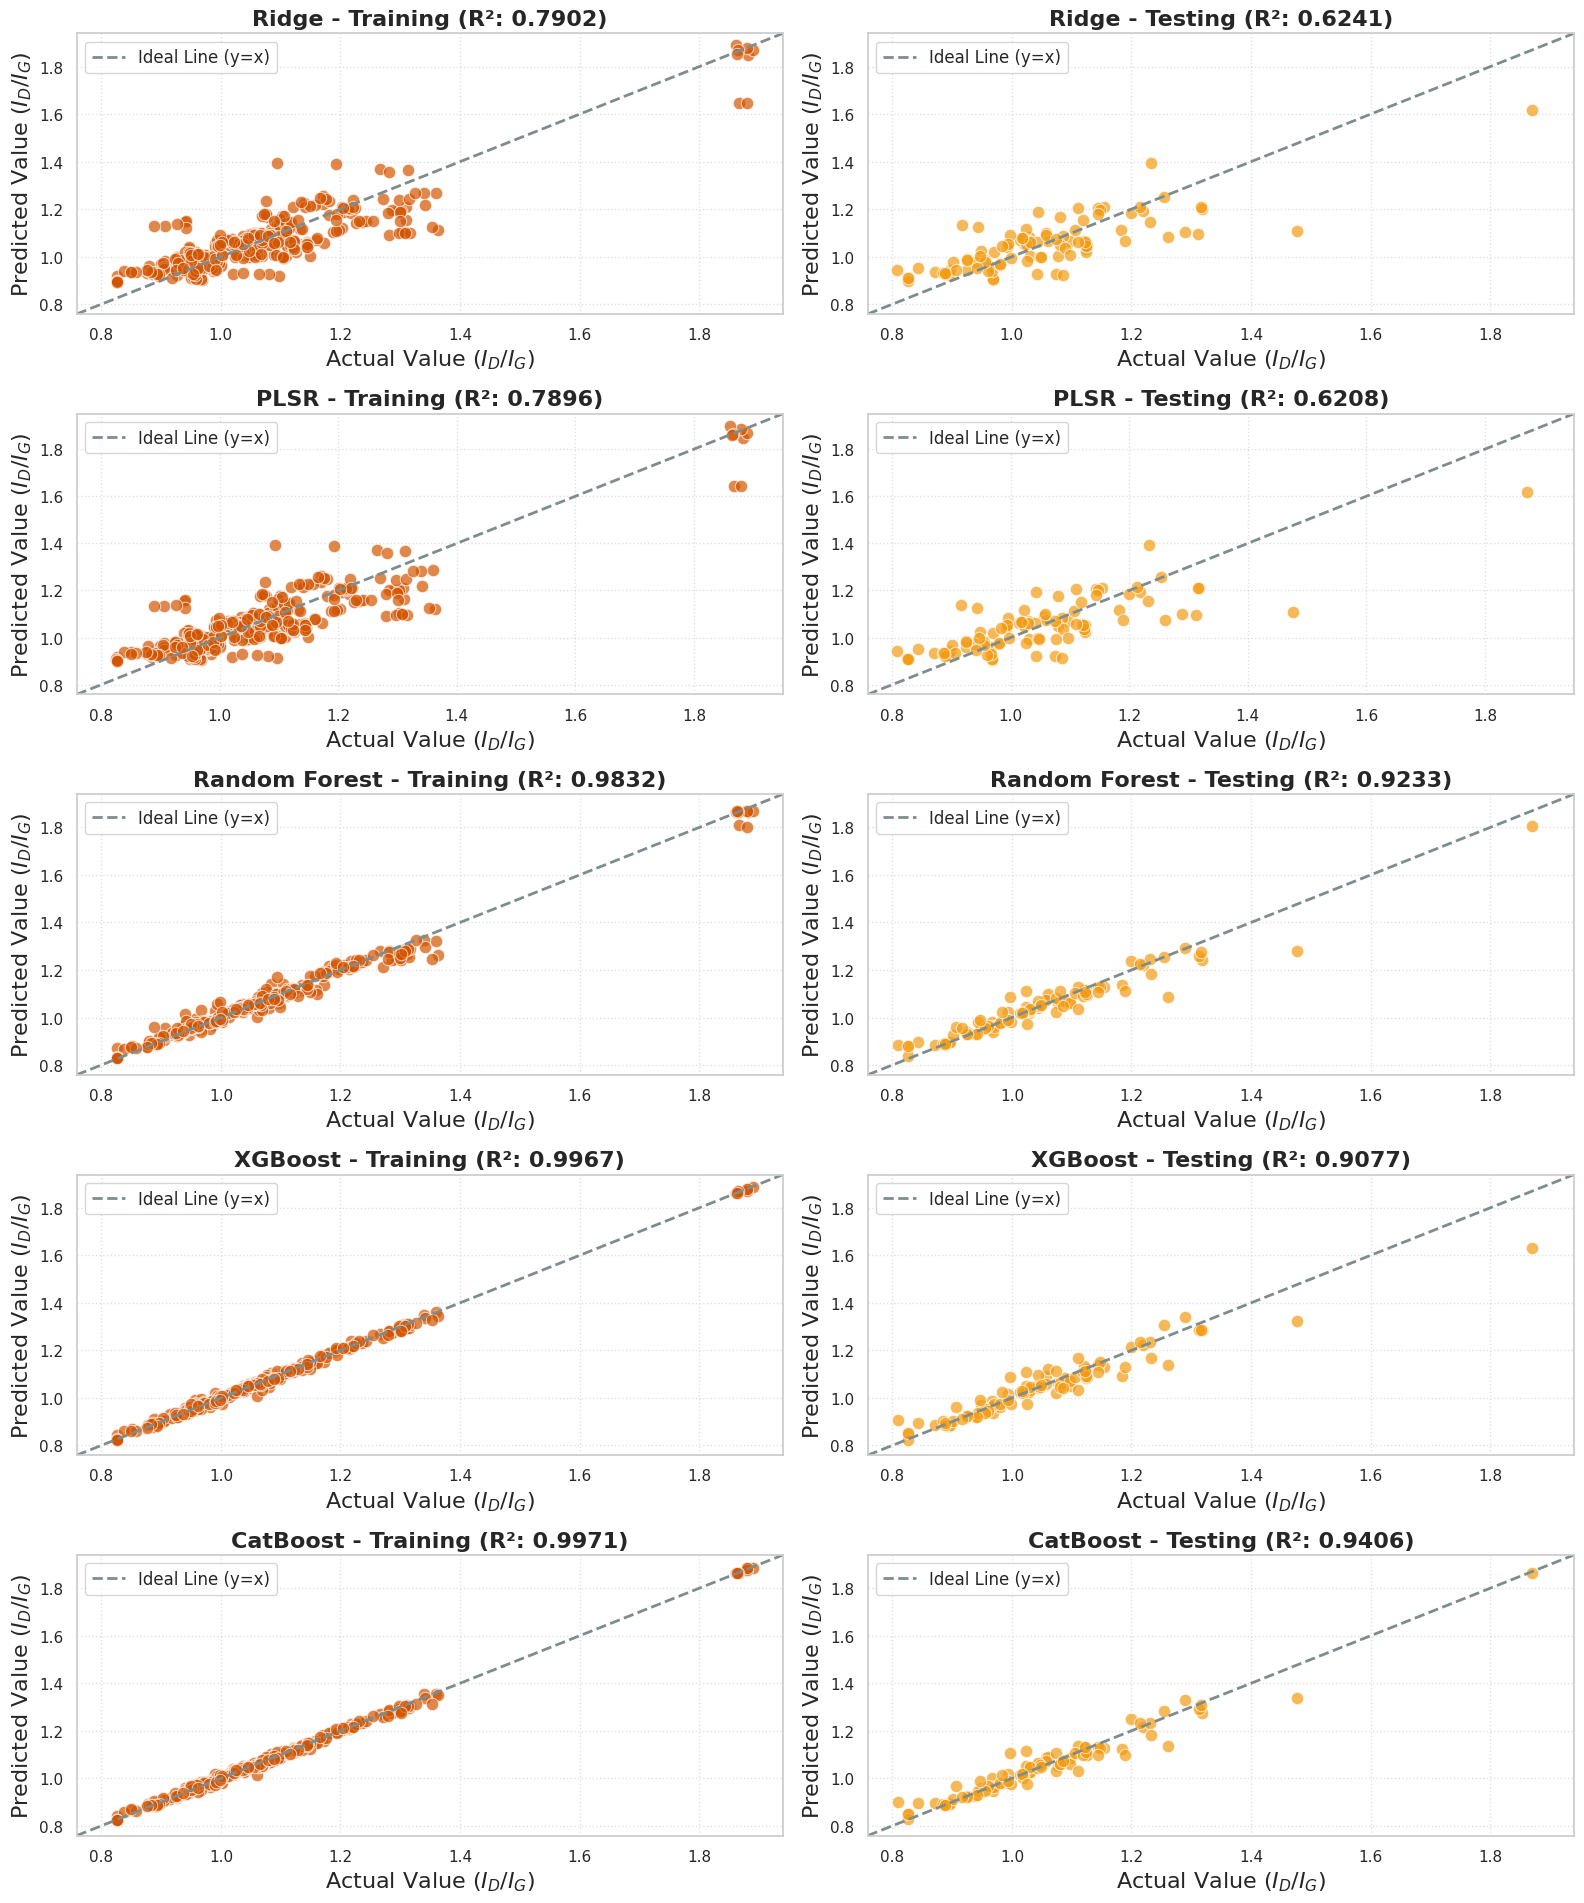

In [57]:
# ==========================================================
# Parity Plot Analysis (Maple Theme)
# ==========================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_ptb,
    y_ptb,
    test_size=0.20,
    stratify=df["biomass"],
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(5, 2, figsize=(16, 20))

# Autumn-maple colors for scatter points
color_train = '#d35400'  # Burnt orange
color_test = '#f39c12'   # Warm gold / amber

for idx, (name, model) in enumerate(tuned_models.items()):
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])
    pipe.fit(X_train_p, y_train_p)

    pred_train = pipe.predict(X_train_p)
    pred_test = pipe.predict(X_test_p)

    r2_train = r2_score(y_train_p, pred_train)
    r2_test = r2_score(y_test_p, pred_test)

    min_val = min(y_ptb.min(), pred_train.min(), pred_test.min()) - 0.05
    max_val = max(y_ptb.max(), pred_train.max(), pred_test.max()) + 0.05

    # TRAINING PLOT
    ax_tr = axes[idx, 0]
    sns.scatterplot(x=y_train_p, y=pred_train, alpha=0.7, color=color_train, edgecolor='w', s=80, ax=ax_tr)
    ax_tr.plot([min_val, max_val], [min_val, max_val], color='#7f8c8d', linestyle='--', linewidth=2, label='Ideal Line (y=x)')
    ax_tr.set_title(f"{name} - Training (R²: {r2_train:.4f})", fontsize=16, fontweight='bold')
    ax_tr.set_xlabel("Actual Value ($I_D/I_G$)", fontsize=16)
    ax_tr.set_ylabel("Predicted Value ($I_D/I_G$)", fontsize=16)
    ax_tr.set_xlim(min_val, max_val)
    ax_tr.set_ylim(min_val, max_val)
    ax_tr.grid(True, linestyle=':', alpha=0.6)
    ax_tr.legend(loc='upper left', fontsize=12)

    # TESTING PLOT
    ax_te = axes[idx, 1]
    sns.scatterplot(x=y_test_p, y=pred_test, alpha=0.7, color=color_test, edgecolor='w', s=80, ax=ax_te)
    ax_te.plot([min_val, max_val], [min_val, max_val], color='#7f8c8d', linestyle='--', linewidth=2, label='Ideal Line (y=x)')
    ax_te.set_title(f"{name} - Testing (R²: {r2_test:.4f})", fontsize=16, fontweight='bold')
    ax_te.set_xlabel("Actual Value ($I_D/I_G$)", fontsize=16)
    ax_te.set_ylabel("Predicted Value ($I_D/I_G$)", fontsize=16)
    ax_te.set_xlim(min_val, max_val)
    ax_te.set_ylim(min_val, max_val)
    ax_te.grid(True, linestyle=':', alpha=0.6)
    ax_te.legend(loc='upper left', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

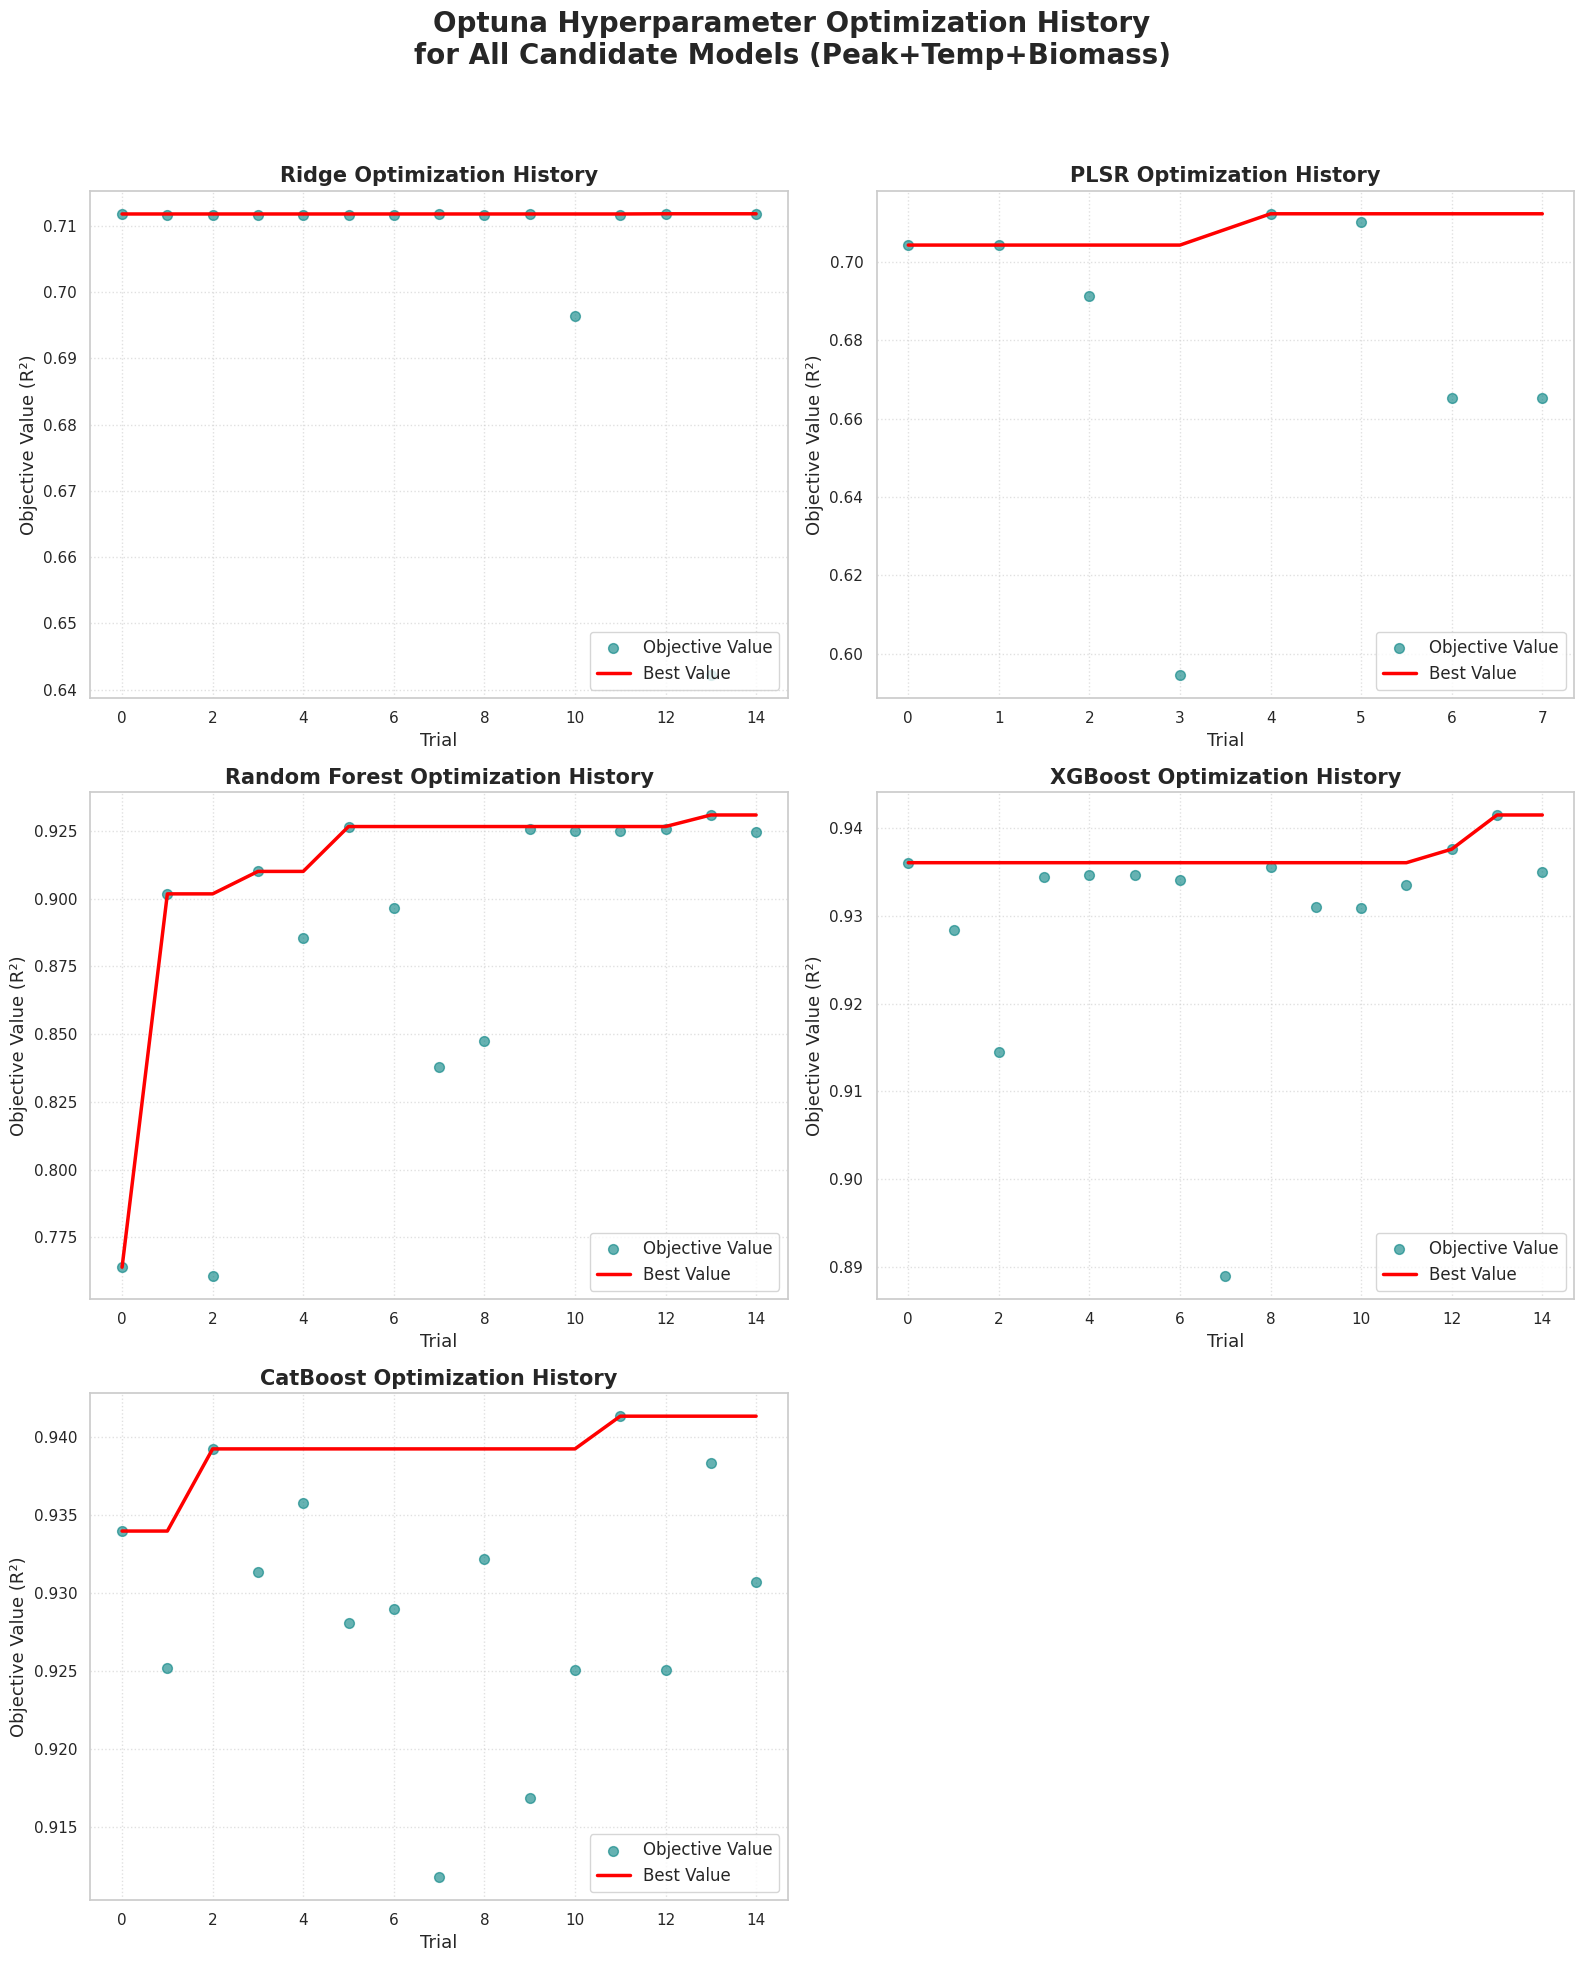

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style
sns.set_theme(style="whitegrid")

def plot_custom_optuna_history(study, ax, title):
    """
    Plots optimization history with enlarged font labels and trial values.
    """
    df_trials = study.trials_dataframe()

    # Filter out any non-complete trials just in case
    df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
    df_complete['trial_number'] = df_complete['number']

    # Calculate cumulative running maximum
    df_complete['running_best'] = df_complete['value'].cummax()

    # Plot individual trial values
    ax.scatter(df_complete['trial_number'], df_complete['value'],
               color='teal', alpha=0.6, s=50, label='Objective Value')

    # Plot running best line
    ax.plot(df_complete['trial_number'], df_complete['running_best'],
            color='red', linestyle='-', linewidth=2.5, label='Best Value')

    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel("Trial", fontsize=13)
    ax.set_ylabel("Objective Value (R²)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.legend(loc='lower right', fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)

# Create a multi-plot layout to display optimization history for all 5 studies
fig, axes = plt.subplots(3, 2, figsize=(16, 20))
fig.suptitle("Optuna Hyperparameter Optimization History\nfor All Candidate Models (Peak+Temp+Biomass)", fontsize=20, fontweight='bold', y=0.98)

# 1. Ridge
plot_custom_optuna_history(study_ridge, axes[0, 0], "Ridge Optimization History")

# 2. PLSR
plot_custom_optuna_history(study_plsr, axes[0, 1], "PLSR Optimization History")

# 3. Random Forest
plot_custom_optuna_history(study_rf_ptb, axes[1, 0], "Random Forest Optimization History")

# 4. XGBoost
plot_custom_optuna_history(study_xgb, axes[1, 1], "XGBoost Optimization History")

# 5. CatBoost
plot_custom_optuna_history(study_cat, axes[2, 0], "CatBoost Optimization History")

# Remove the empty subplot at the bottom right
fig.delaxes(axes[2, 1])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [29]:
# ==========================================================
# PART 15. Best Optimized Candidate Model
# ==========================================================

# Retrieve the absolute best configuration from our Optuna tuning benchmark
best_tuned_model_name = df_tuned_benchmark.iloc[0]["Model"]
best_tuned_r2 = df_tuned_benchmark.iloc[0]["Best R²"]
best_tuned_params_dict = best_tuned_params[best_tuned_model_name]

print("="*65)
print(f"Best Optimized Model  : {best_tuned_model_name}")
print(f"Optimized Feature Set : Peak+Temp+Biomass")
print(f"Best Cross-Val R²     : {best_tuned_r2:.4f}")
print(f"Optimal Parameters    : {best_tuned_params_dict}")
print("="*65)

Best Optimized Model  : XGBoost
Optimized Feature Set : Peak+Temp+Biomass
Best Cross-Val R²     : 0.9415
Optimal Parameters    : {'n_estimators': 307, 'max_depth': 3, 'learning_rate': 0.11058611149448229, 'subsample': 0.7355131641575576, 'colsample_bytree': 0.7537366145034304}


In [30]:
results["Generalization_Gap"] = (
    results["Train_R2"] - results["Test_R2"]
)

```markdown
# ==========================================================
# PART 15A. Tuned Models Stability & Consistency Analysis
# ==========================================================
Pada bagian ini, kita mengevaluasi stabilitas dan konsistensi prediksi dari lima model kandidat yang telah dioptimalkan.

Kami menggunakan **Stratified 5-Fold Cross-Validation** (yang distratifikasikan berdasarkan kategori `biomass`) untuk mengukur rata-rata (*Mean*) dan standar deviasi (*Standard Deviation*) dari metrik $R^2$ dan RMSE. Nilai standar deviasi yang rendah menunjukkan model memiliki variansi yang kecil dan stabilitas tinggi terhadap perubahan subset data latih. Berdasarkan hasil tuning Optuna, **XGBoost** merupakan model terbaik dengan performa paling unggul.
```

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate

stability_results = []

print("Evaluating stability metrics for all tuned models across 5 folds...")

for name, model in tuned_models.items():
    pipe = Pipeline([("prep", preprocessor_ptb), ("model", model)])

    # Jalankan cross-validation
    cv_res = cross_validate(
        pipe,
        X_ptb,
        y_ptb,
        cv=cv_splits,
        scoring={
            "r2": "r2",
            "neg_rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    r2_scores = cv_res["test_r2"]
    rmse_scores = -cv_res["test_neg_rmse"]

    stability_results.append({
        "Model": name,
        "Mean R²": r2_scores.mean(),
        "Std R²": r2_scores.std(),
        "Mean RMSE": rmse_scores.mean(),
        "Std RMSE": rmse_scores.std()
    })

# Buat DataFrame hasil evaluasi stabilitas
df_stability = pd.DataFrame(stability_results).sort_values(by="Mean R²", ascending=False).reset_index(drop=True)

# Tampilkan tabel
display(df_stability.style.background_gradient(subset=["Mean R²"], cmap="Greens").background_gradient(subset=["Std R²", "Std RMSE"], cmap="Reds"))

Evaluating stability metrics for all tuned models across 5 folds...


,Model,Mean R²,Std R²,Mean RMSE,Std RMSE
0,XGBoost,0.941510,0.030805,0.035443,0.003125
1,CatBoost,0.941356,0.040366,0.034587,0.004714
2,Random Forest,0.930946,0.044702,0.038117,0.006234
3,PLSR,0.712269,0.102196,0.080744,0.001339
4,Ridge,0.711806,0.106841,0.080643,0.001447


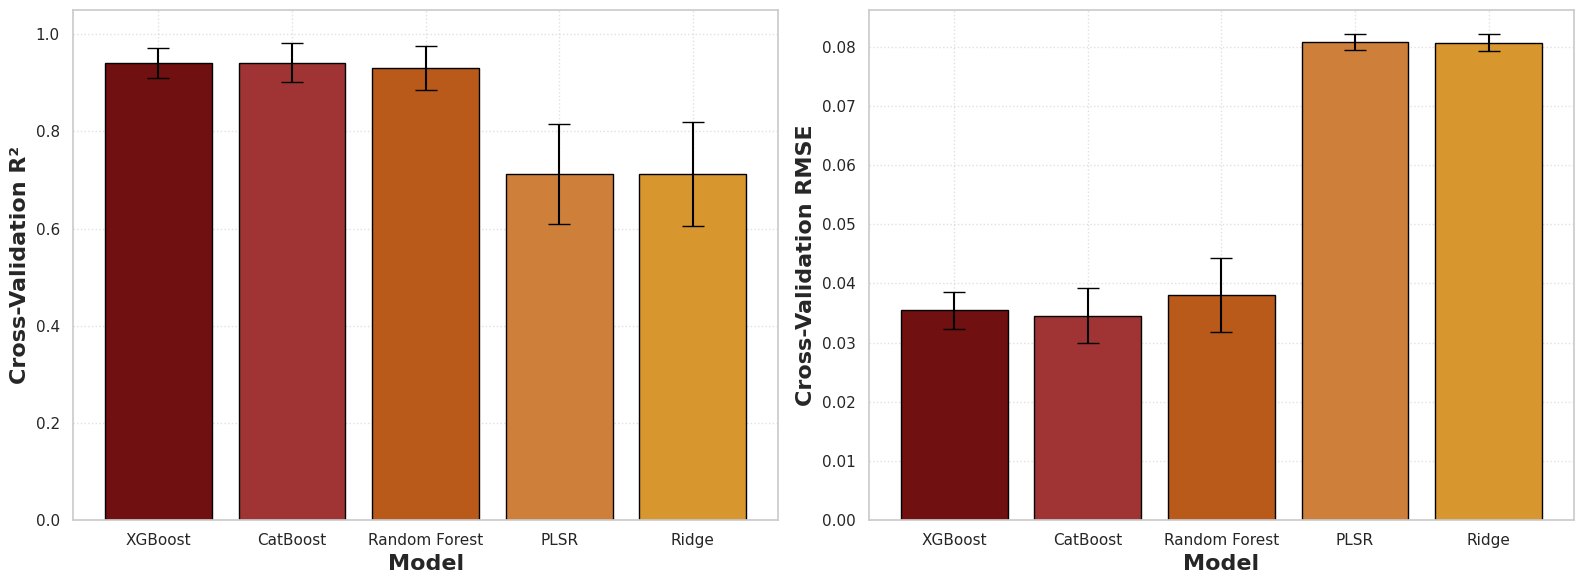

In [52]:
# ==========================================================
# Model Stability and Consistency Analysis (Maple Theme)
# ==========================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Golden/brown maple palette
maple_palette = ["#800000", "#b22222", "#d35400", "#e67e22", "#f39c12"]

# 1. Barplot untuk R² dengan error bar (Std)
sns.barplot(
    x="Model",
    y="Mean R²",
    data=df_stability,
    ax=ax1,
    palette=maple_palette,
    hue="Model",
    legend=False,
    edgecolor="black"
)
ax1.errorbar(
    x=df_stability["Model"],
    y=df_stability["Mean R²"],
    yerr=df_stability["Std R²"],
    fmt='none',
    c='black',
    capsize=8,
    label='Standard Deviation'
)
ax1.set_ylabel("Cross-Validation R²", fontsize=16, fontweight='bold')
ax1.set_xlabel("Model", fontsize=16, fontweight='bold')
ax1.set_ylim(0, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Barplot untuk RMSE dengan error bar (Std)
sns.barplot(
    x="Model",
    y="Mean RMSE",
    data=df_stability,
    ax=ax2,
    palette=maple_palette,
    hue="Model",
    legend=False,
    edgecolor="black"
)
ax2.errorbar(
    x=df_stability["Model"],
    y=df_stability["Mean RMSE"],
    yerr=df_stability["Std RMSE"],
    fmt='none',
    c='black',
    capsize=8
)
ax2.set_ylabel("Cross-Validation RMSE", fontsize=16, fontweight='bold')
ax2.set_xlabel("Model", fontsize=16, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [33]:
# ==========================================================
# PART 16. PCA Feature Compression
# ==========================================================

from sklearn.decomposition import PCA

X_ftir = df[ftir_cols]

y = df[target]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_ftir)

pca_dimensions = [
    10,
    20,
    29,
    50,
    100
]

pca_features = {}

for n in pca_dimensions:

    pca = PCA(
        n_components=n,
        random_state=RANDOM_STATE
    )

    X_pca = pca.fit_transform(X_scaled)

    cols = [f"PC{i+1}" for i in range(n)]

    temp_df = pd.DataFrame(
        X_pca,
        columns=cols
    )

    temp_df["ID/IG"] = y

    pca_features[n] = temp_df

    print(
        f"PCA {n} --> "
        f"{pca.explained_variance_ratio_.sum()*100:.2f}% variance"
    )

PCA 10 --> 83.05% variance
PCA 20 --> 92.33% variance
PCA 29 --> 95.14% variance
PCA 50 --> 98.04% variance
PCA 100 --> 99.66% variance


In [34]:
from sklearn.base import clone

def evaluate_pca_model(
    model,
    X,
    y
):

    X_train, X_test, y_train, y_test = train_test_split(

        X,

        y,

        test_size=0.20,

        random_state=42

    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)

    X_test = scaler.transform(X_test)

    model = clone(model)

    model.fit(
        X_train,
        y_train
    )

    pred_train = model.predict(X_train)

    pred_test = model.predict(X_test)

    return {

        "Train_R2":
        r2_score(y_train,pred_train),

        "Test_R2":
        r2_score(y_test,pred_test),

        "RMSE":
        np.sqrt(
            mean_squared_error(
                y_test,
                pred_test
            )
        ),

        "MAE":
        mean_absolute_error(
            y_test,
            pred_test
        )

    }

In [35]:
# ==========================================================
# PART 18. PCA Benchmark: Best Tuned Linear vs. Non-Linear Models
# ==========================================================
import pandas as pd
import numpy as np

# Identifikasi Model Linear Terbaik dari hasil tuning
linear_candidates = ["Ridge", "PLSR"]
df_linear = df_tuned_benchmark[df_tuned_benchmark["Model"].isin(linear_candidates)]
best_linear_name = df_linear.iloc[0]["Model"] if not df_linear.empty else "Ridge"
best_linear_params = best_tuned_params[best_linear_name]

# Identifikasi Model Non-Linear Terbaik dari hasil tuning
nonlinear_candidates = ["Random Forest", "XGBoost", "CatBoost"]
df_nonlinear = df_tuned_benchmark[df_tuned_benchmark["Model"].isin(nonlinear_candidates)]
best_nonlinear_name = df_nonlinear.iloc[0]["Model"] if not df_nonlinear.empty else "CatBoost"
best_nonlinear_params = best_tuned_params[best_nonlinear_name]

print("="*65)
print(f"Best Tuned Linear Model      : {best_linear_name} with params: {best_linear_params}")
print(f"Best Tuned Non-Linear Model  : {best_nonlinear_name} with params: {best_nonlinear_params}")
print("="*65)

# Inisialisasi kedua model terbaik
if best_linear_name == "Ridge":
    model_linear = Ridge(**best_linear_params, random_state=RANDOM_STATE)
elif best_linear_name == "PLSR":
    model_linear = PLSRegression(**best_linear_params)

if best_nonlinear_name == "Random Forest":
    model_nonlinear = RandomForestRegressor(**best_nonlinear_params, random_state=RANDOM_STATE)
elif best_nonlinear_name == "XGBoost":
    model_nonlinear = XGBRegressor(**best_nonlinear_params, random_state=RANDOM_STATE, verbosity=0)
elif best_nonlinear_name == "CatBoost":
    model_nonlinear = CatBoostRegressor(**best_nonlinear_params, random_seed=RANDOM_STATE, verbose=False)

benchmark_list = []
candidate_models = {
    f"{best_linear_name} (Linear)": model_linear,
    f"{best_nonlinear_name} (Non-Linear)": model_nonlinear
}

# Jalankan evaluasi pada setiap dimensi PCA
for n in pca_dimensions:
    data_pca = pca_features[n]
    X_pca_dims = data_pca.drop(columns="ID/IG")
    y_pca_dims = data_pca["ID/IG"]

    for name, model in candidate_models.items():
        score = evaluate_pca_model(model, X_pca_dims, y_pca_dims)
        score["Representation"] = f"PCA {n}"
        score["Model"] = name
        benchmark_list.append(score)

benchmark = pd.DataFrame(benchmark_list)
display(benchmark.style.background_gradient(subset=["Test_R2"], cmap="Greens").background_gradient(subset=["RMSE"], cmap="Reds_r"))

Best Tuned Linear Model      : PLSR with params: {'n_components': 8}
Best Tuned Non-Linear Model  : XGBoost with params: {'n_estimators': 307, 'max_depth': 3, 'learning_rate': 0.11058611149448229, 'subsample': 0.7355131641575576, 'colsample_bytree': 0.7537366145034304}


,Train_R2,Test_R2,RMSE,MAE,Representation,Model
0,0.365085,0.413045,0.152974,0.090241,PCA 10,PLSR (Linear)
1,0.995567,0.794560,0.090502,0.040155,PCA 10,XGBoost (Non-Linear)
2,0.418837,0.458506,0.146931,0.087245,PCA 20,PLSR (Linear)
3,0.996614,0.863771,0.073697,0.037945,PCA 20,XGBoost (Non-Linear)
4,0.489742,0.428929,0.150890,0.087908,PCA 29,PLSR (Linear)
5,0.997046,0.777278,0.094232,0.041414,PCA 29,XGBoost (Non-Linear)
6,0.627114,0.439301,0.149514,0.090236,PCA 50,PLSR (Linear)
7,0.997617,0.821158,0.084440,0.040858,PCA 50,XGBoost (Non-Linear)
8,0.837289,0.646724,0.118679,0.081719,PCA 100,PLSR (Linear)
9,0.998359,0.805166,0.088135,0.041496,PCA 100,XGBoost (Non-Linear)


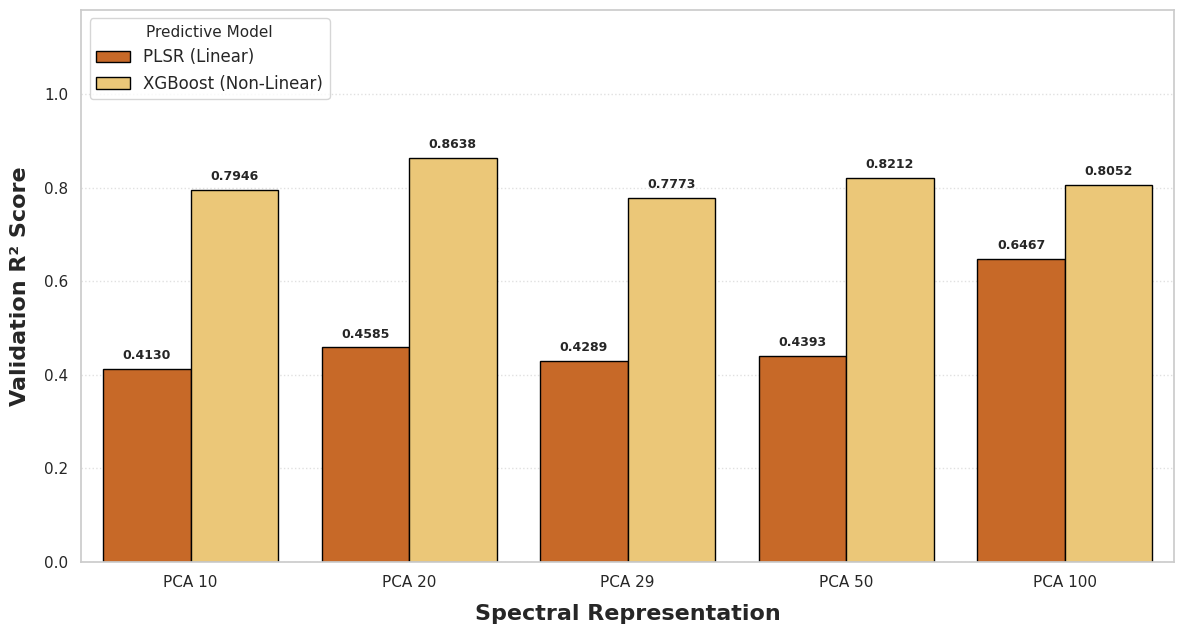

In [61]:
# ==========================================================
# Spectral Representation Benchmark (Maple Theme) - Fixed Layout
# ==========================================================
plt.figure(figsize=(12, 6.5))

ax = sns.barplot(
    data=benchmark,
    x="Representation",
    y="Test_R2",
    hue="Model",
    palette="YlOrBr_r",  # Gradasi maple hangat
    edgecolor="black"
)

# Menambahkan anotasi angka di atas setiap batang grafik
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold')

plt.xlabel("Spectral Representation", fontsize=16, fontweight='bold', labelpad=10)
plt.ylabel("Validation R² Score", fontsize=16, fontweight='bold', labelpad=10)
plt.ylim(0, 1.18)

# Meletakkan legenda di dalam plot pada posisi pojok kiri atas (upper left)
# dengan frame transparan (alpha) agar tidak menghalangi visualisasi
plt.legend(
    title="Predictive Model",
    loc='upper left',
    fontsize=12,
    title_fontsize=11,
    framealpha=0.8
)

plt.grid(True, linestyle=':', alpha=0.6, axis='y')
plt.tight_layout()
plt.show()

In [37]:
# ==========================================================
# PART 19. Comparison: Physical Peaks vs. Spectral PCA (PLSR vs. CatBoost Only)
# ==========================================================

# 1. Ambil performa PLSR dan CatBoost dari set fitur fisik (Peak) sebagai representasi murni Fitur Fisik
peak_models = results[(results["Feature_Set"] == "Peak") & (results["Model"].isin(["PLSR", "CatBoost"]))].copy()
if not peak_models.empty:
    peak_models["Representation"] = "Physical Peaks"
    # Ubah nama model agar konsisten secara label klasifikasi model
    peak_models["Model"] = peak_models["Model"].map({
        "PLSR": "PLSR (Linear)",
        "CatBoost": "CatBoost (Non-Linear)"
    })

# 2. Ambil benchmark PCA kita dan saring hanya untuk PLSR (Linear) vs CatBoost (Non-Linear)
pca_only_benchmark = benchmark[benchmark["Model"].isin(["PLSR (Linear)", "CatBoost (Non-Linear)"])].copy()

# 3. Gabungkan untuk visualisasi komparatif yang simetris
comparison_frames = [
    pca_only_benchmark[["Train_R2", "Test_R2", "RMSE", "MAE", "Representation", "Model"]]
]
if not peak_models.empty:
    comparison_frames.append(peak_models[["Train_R2", "Test_R2", "RMSE", "MAE", "Representation", "Model"]])

comparison = pd.concat(comparison_frames, ignore_index=True)

# Tampilkan tabel komparasi terurut berdasarkan R2 Pengujian
display(comparison.sort_values(by="Test_R2", ascending=False).style.background_gradient(subset=["Test_R2"], cmap="Greens"))

,Train_R2,Test_R2,RMSE,MAE,Representation,Model
5,0.996406,0.924289,0.054941,0.033028,Physical Peaks,CatBoost (Non-Linear)
6,0.517773,0.766847,0.096413,0.074838,Physical Peaks,PLSR (Linear)
4,0.837289,0.646724,0.118679,0.081719,PCA 100,PLSR (Linear)
1,0.418837,0.458506,0.146931,0.087245,PCA 20,PLSR (Linear)
3,0.627114,0.439301,0.149514,0.090236,PCA 50,PLSR (Linear)
2,0.489742,0.428929,0.150890,0.087908,PCA 29,PLSR (Linear)
0,0.365085,0.413045,0.152974,0.090241,PCA 10,PLSR (Linear)


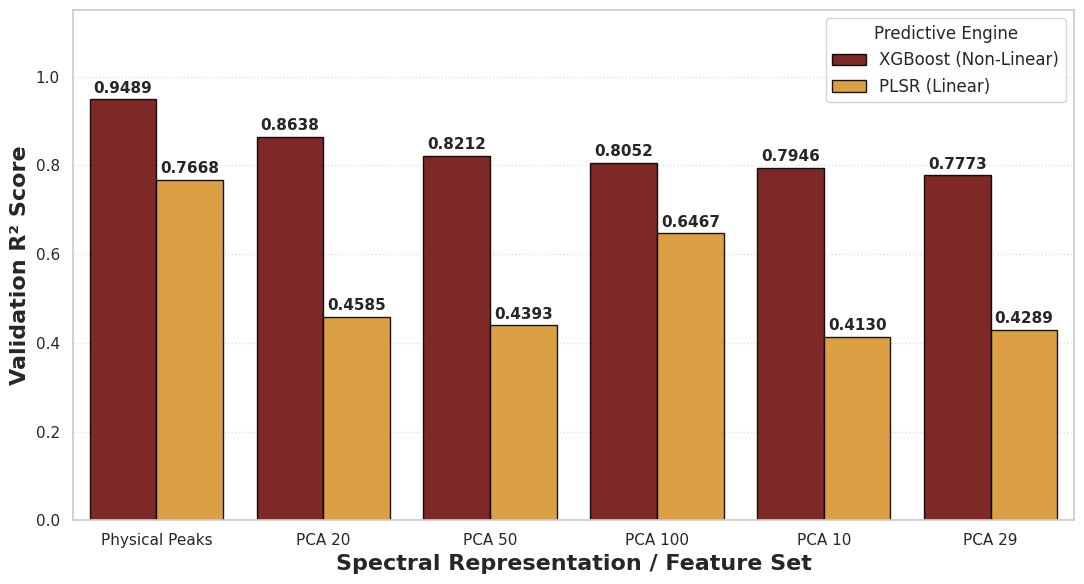

In [64]:
# ==========================================================
# Symmetric Benchmark Plot (Maple Theme - Fixed Overwritten Variable)
# ==========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Membangun kembali DataFrame perbandingan spektroskopi secara lokal
# untuk menghindari masalah variabel yang tertimpa di sel lain
peak_models_local = results[(results["Feature_Set"] == "Peak") & (results["Model"].isin(["PLSR", "XGBoost"]))].copy()
if not peak_models_local.empty:
    peak_models_local["Representation"] = "Physical Peaks"
    peak_models_local["Model"] = peak_models_local["Model"].map({
        "PLSR": "PLSR (Linear)",
        "XGBoost": "XGBoost (Non-Linear)"
    })

pca_only_benchmark_local = benchmark[benchmark["Model"].isin(["PLSR (Linear)", "XGBoost (Non-Linear)"])].copy()

comparison_frames_local = [
    pca_only_benchmark_local[["Train_R2", "Test_R2", "RMSE", "MAE", "Representation", "Model"]]
]
if not peak_models_local.empty:
    comparison_frames_local.append(peak_models_local[["Train_R2", "Test_R2", "RMSE", "MAE", "Representation", "Model"]])

spectral_comparison = pd.concat(comparison_frames_local, ignore_index=True)

# Menentukan kolom R2 pengujian secara dinamis
sort_col = "Test_R2" if "Test_R2" in spectral_comparison.columns else "Test R²"
plot_data = spectral_comparison.sort_values(by=sort_col, ascending=False)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=plot_data,
    x="Representation",
    y=sort_col,
    hue="Model",
    palette={"PLSR (Linear)": "#f39c12", "XGBoost (Non-Linear)": "#800000"},  # Diperbaiki agar sesuai dengan nama model yang telah dipetakan
    edgecolor="black",
    alpha=0.9
)

ax = plt.gca()
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=11, fontweight='bold')

plt.xlabel("Spectral Representation / Feature Set", fontsize=16, fontweight='bold')
plt.ylabel("Validation R² Score", fontsize=16, fontweight='bold')
plt.ylim(0, 1.15)
plt.grid(True, linestyle=":", alpha=0.6, axis='y')
plt.legend(title="Predictive Engine", loc="upper right", fontsize=12)

plt.tight_layout()
plt.show()

In [39]:
# ==========================================================
# PART 31. Group-wise Validation Setup
# ==========================================================

from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

# Menentukan variabel dasar untuk model terbaik teroptimasi
X_opt = df[feature_sets["Peak+Temp+Biomass"]]
y_opt = df[target]
preprocessor_opt = build_preprocessor(feature_sets["Peak+Temp+Biomass"])

# Menggunakan parameter terbaik dari hasil Optuna Tuning untuk XGBoost
tuned_best_model = XGBRegressor(**best_tuned_params["XGBoost"], random_state=RANDOM_STATE, verbosity=0)

# Menggunakan kolom 'biomass' sebagai basis pengelompokkan (Groups)
groups = df["biomass"]

print("Distribusi Sampel per Jenis Biomass:")
print("-" * 40)
print(groups.value_counts())
print("-" * 40)
print(f"Total kelompok biomass unik: {groups.nunique()}")

Distribusi Sampel per Jenis Biomass:
----------------------------------------
biomass
Sugar-apple Seed      81
Corncob               81
Bittermelon Leaves    81
Castor Seed           81
Sappanwood            81
Palm Kernel Meal      81
Name: count, dtype: int64
----------------------------------------
Total kelompok biomass unik: 6


In [40]:
# ==========================================================
# PART 32. Biomass-wise Validation (Optimized XGBoost Model)
# ==========================================================

# Menggunakan GroupKFold dengan jumlah split sebanyak jumlah biomass unik
group_cv = GroupKFold(n_splits=groups.nunique())

group_scores = cross_validate(
    Pipeline([
        ("prep", preprocessor_opt),
        ("model", tuned_best_model)
    ]),
    X_opt,
    y_opt,
    cv=group_cv,
    groups=groups,
    scoring=[
        "r2",
        "neg_root_mean_squared_error",
        "neg_mean_absolute_error"
    ],
    return_train_score=True,
    n_jobs=-1
)

group_summary = pd.DataFrame({
    "Metric": [
        "Train R²",
        "Test R²",
        "RMSE",
        "MAE"
    ],
    "Mean": [
        group_scores["train_r2"].mean(),
        group_scores["test_r2"].mean(),
        -group_scores["test_neg_root_mean_squared_error"].mean(),
        -group_scores["test_neg_mean_absolute_error"].mean()
    ],
    "Std": [
        group_scores["train_r2"].std(),
        group_scores["test_r2"].std(),
        group_scores["test_neg_root_mean_squared_error"].std(),
        group_scores["test_neg_mean_absolute_error"].std()
    ]
})

print("Hasil Evaluasi Biomass-wise (Leave-One-Group-Out):")
display(group_summary.style.background_gradient(subset=["Mean"], cmap="Blues"))

Hasil Evaluasi Biomass-wise (Leave-One-Group-Out):


,Metric,Mean,Std
0,Train R²,0.995803,0.001476
1,Test R²,-0.542088,0.836301
2,RMSE,0.128177,0.099774
3,MAE,0.101961,0.072075


In [41]:
# ==========================================================
# PART 33. Validation Comparison (Sample-wise vs Biomass-wise)
# ==========================================================

# Mengambil metrik stabil dari df_stability untuk model XGBoost (Sample-wise)
sample_wise_r2 = df_stability.loc[df_stability["Model"] == "XGBoost", "Mean R²"].values[0]
sample_wise_rmse = df_stability.loc[df_stability["Model"] == "XGBoost", "Mean RMSE"].values[0]

# Mengambil metrik dari group_summary untuk Biomass-wise (GroupKFold)
biomass_wise_r2 = group_summary.loc[group_summary["Metric"] == "Test R²", "Mean"].values[0]
biomass_wise_rmse = group_summary.loc[group_summary["Metric"] == "RMSE", "Mean"].values[0]

comparison = pd.DataFrame({
    "Validation": [
        "Sample-wise (Stratified 5-Fold)",
        "Biomass-wise (GroupKFold)"
    ],
    "Test R²": [
        sample_wise_r2,
        biomass_wise_r2
    ],
    "RMSE": [
        sample_wise_rmse,
        biomass_wise_rmse
    ]
})

print("Tabel Komparasi Metode Validasi:")
display(comparison.style.background_gradient(subset=["Test R²"], cmap="Greens").background_gradient(subset=["RMSE"], cmap="Reds_r"))

Tabel Komparasi Metode Validasi:


,Validation,Test R²,RMSE
0,Sample-wise (Stratified 5-Fold),0.941510,0.035443
1,Biomass-wise (GroupKFold),-0.542088,0.128177


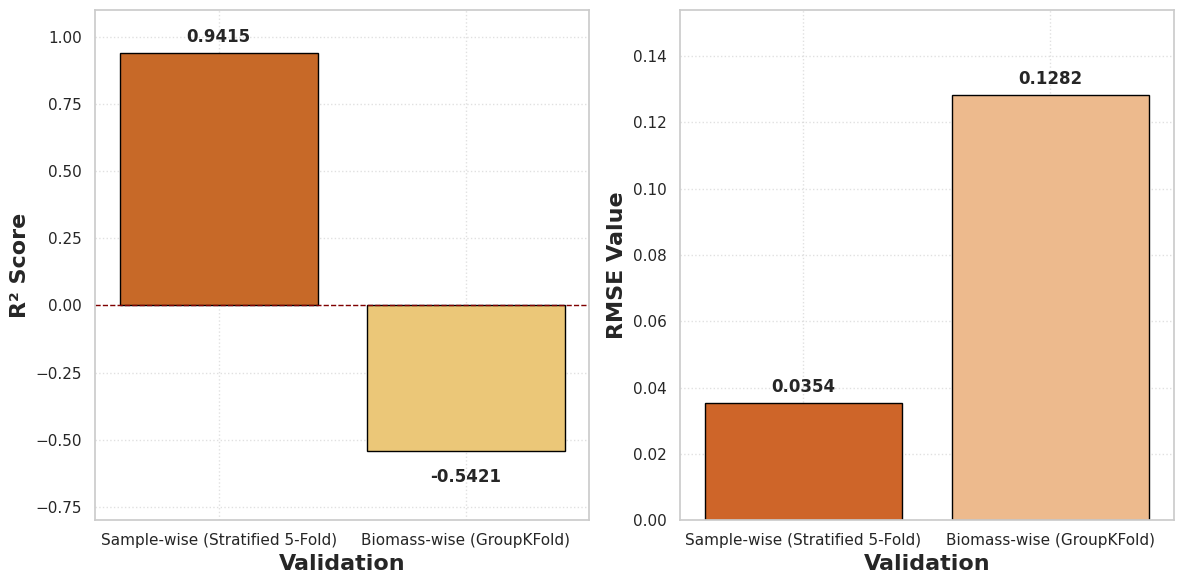

In [66]:
# ==========================================================
# Validation Generalization Gap Comparison (Maple Theme)
# ==========================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Plot R2 with warm honey-maple syrup palette
sns.barplot(data=comparison, x="Validation", y="Test R²", palette="YlOrBr_r", ax=ax1, edgecolor="black")
ax1.set_ylabel("R² Score", fontsize=16, fontweight='bold')
ax1.set_xlabel("Validation", fontsize=16, fontweight='bold')
ax1.set_ylim(-0.8, 1.1)
ax1.axhline(0, color='#800000', linestyle='--', linewidth=1)
ax1.grid(True, linestyle=':', alpha=0.6)

for p in ax1.patches:
    val = p.get_height()
    ax1.annotate(f"{val:.4f}", (p.get_x() + p.get_width() / 2., val),
                ha='center', va='bottom' if val >= 0 else 'top',
                xytext=(0, 5 if val >= 0 else -12), textcoords='offset points', fontweight='bold')

# Plot RMSE with deep warm copper-maple leaf palette
sns.barplot(data=comparison, x="Validation", y="RMSE", palette="Oranges_r", ax=ax2, edgecolor="black")
ax2.set_ylabel("RMSE Value", fontsize=16, fontweight='bold')
ax2.set_xlabel("Validation", fontsize=16, fontweight='bold')
ax2.set_ylim(0, max(comparison["RMSE"]) * 1.2)
ax2.grid(True, linestyle=':', alpha=0.6)

for p in ax2.patches:
    val = p.get_height()
    ax2.annotate(f"{val:.4f}", (p.get_x() + p.get_width() / 2., val),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

In [43]:
# ==========================================================
# PART 34. Learning Curve (Optimized Model)
# ==========================================================

from sklearn.model_selection import learning_curve

best_pipeline = Pipeline([
    ("prep", preprocessor_opt),
    ("model", tuned_best_model)
])

train_sizes, train_scores, test_scores = learning_curve(
    estimator=best_pipeline,
    X=X_opt,
    y=y_opt,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

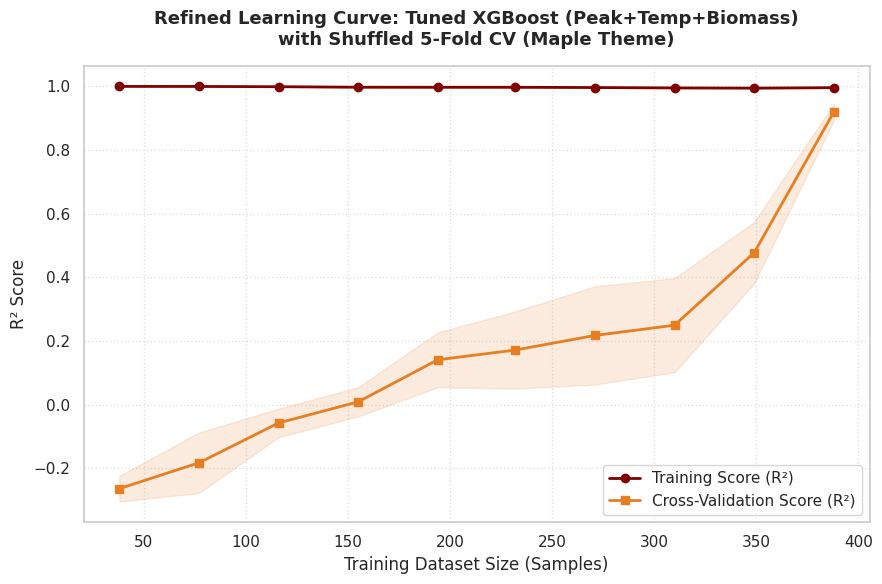

In [44]:
# ==========================================================
# PART 34. Learning Curve Computation & Visualization (Refined & Maple Theme)
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import Pipeline

stable_cv = KFold(n_splits=5, shuffle=True, random_state=42)

best_pipeline = Pipeline([
    ("prep", preprocessor_opt),
    ("model", tuned_best_model)
])

train_sizes, train_scores, test_scores = learning_curve(
    estimator=best_pipeline,
    X=X_opt,
    y=y_opt,
    cv=stable_cv,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

plt.figure(figsize=(9, 6))

# Autumn-maple leaf line colors
plt.plot(train_sizes, train_mean, marker='o', linestyle='-', color='#800000', linewidth=2, label="Training Score (R²)")
plt.plot(train_sizes, test_mean, marker='s', linestyle='-', color='#e67e22', linewidth=2, label="Cross-Validation Score (R²)")

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#800000')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='#e67e22')

plt.title("Refined Learning Curve: Tuned XGBoost (Peak+Temp+Biomass)\nwith Shuffled 5-Fold CV (Maple Theme)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Training Dataset Size (Samples)", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

```markdown
# ==========================================================
# PART 35C. Refined Feature Importance: Permutation vs SHAP
# ==========================================================
In this section, we conduct an in-depth model interpretability analysis by comparing **Permutation Feature Importance** (based on global metric drop) and **SHAP (SHapley Additive exPlanations)** (based on local feature attribution).

We first install the `shap` package to extract the feature contribution attributions and then run the unified comparative visualization.
```

In [45]:
!pip install shap

In [46]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# 1. Fit Best Pipeline (XGBoost) on All Data
best_pipeline.fit(X_opt, y_opt)

# 2. Extract Preprocessed Features for SHAP Explainer
preprocessor = best_pipeline.named_steps["prep"]
X_transformed = preprocessor.transform(X_opt)

# Dapatkan nama fitur baru setelah One-Hot Encoding
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_features = list(cat_encoder.get_feature_names_out(["biomass"]))

# Kombinasi nama fitur numerik dan kategorikal
num_features = [col for col in X_opt.columns if col != "biomass"]
feature_names_transformed = num_features + encoded_cat_features

# Konversi ke DataFrame agar visualisasi SHAP memiliki label yang jelas
X_transformed_df = pd.DataFrame(X_transformed, columns=feature_names_transformed)

# 3. Ambil model XGBoost ter-tuning dari pipeline
model_xgb = best_pipeline.named_steps["model"]

# 4. Hitung SHAP Values menggunakan TreeExplainer (XGBoost)
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_transformed_df)

# 5. Hitung Permutation Importance yang lebih presisi dengan 50 repeats
print("Calculating refined Permutation Importance (50 repeats) for Tuned XGBoost...")
perm_refined = permutation_importance(
    best_pipeline,
    X_opt,
    y_opt,
    n_repeats=50,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

df_perm_refined = pd.DataFrame({
    "Feature": X_opt.columns,
    "Importance_Mean": perm_refined.importances_mean,
    "Importance_Std": perm_refined.importances_std
}).sort_values(by="Importance_Mean", ascending=False).reset_index(drop=True)

# Tampilkan tabel Permutation Importance yang dihaluskan
display(df_perm_refined)

Calculating refined Permutation Importance (50 repeats) for Tuned XGBoost...


,Feature,Importance_Mean,Importance_Std
0,biomass,0.319464,0.016278
1,peak_CC_1600,0.230600,0.015661
2,temp,0.143937,0.008350
3,peak_OH,0.070258,0.006147
4,peak_CO_1050,0.054093,0.005785
5,peak_CH_2920,0.033702,0.001486
6,ratio_OH_CC,0.033135,0.002260
7,ratio_CO_CC,0.020950,0.001476
8,ratio_CH_CC,0.018969,0.001275
9,peak_CO_1700,0.017616,0.001249


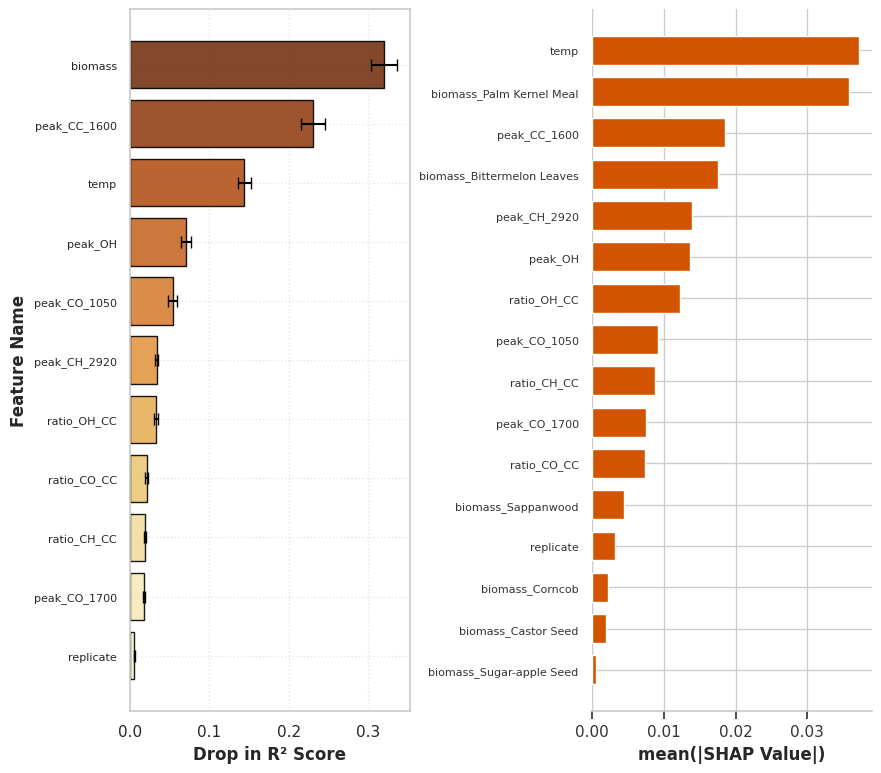

In [73]:
# ==========================================================
# Refined Interpretability Plot: Permutation vs. SHAP (Maple Theme)
# ==========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import shap

# Mengatur figure dengan ukuran proporsional (figsize=(9, 5)) untuk menghindari label bertumpuk
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
# Subplot 1: Refined Permutation Importance dengan gradasi maple emas-perunggu
sns.barplot(
    data=df_perm_refined,
    x="Importance_Mean",
    y="Feature",
    ax=axes[0],
    palette="YlOrBr_r",
    edgecolor="black",
    alpha=0.9
)
axes[0].errorbar(
    x=df_perm_refined["Importance_Mean"],
    y=df_perm_refined["Feature"],
    xerr=df_perm_refined["Importance_Std"],
    fmt='none',
    c='black',
    capsize=4
)
axes[0].set_xlabel("Drop in R² Score", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Feature Name", fontsize=12, fontweight='bold')
axes[0].tick_params(axis='y', labelsize=8)  # Memperkecil sedikit ukuran font agar tidak menumpuk
axes[0].grid(True, linestyle=":", alpha=0.5)

# Subplot 2: SHAP Global Feature Importance dengan warna burnt orange khas daun maple
plt.axes(axes[1])
shap.summary_plot(
    shap_values,
    X_transformed_df,
    plot_type="bar",
    show=False,
    color="#d35400"  # Deep maple burnt orange
)
axes[1].set_xlabel("mean(|SHAP Value|)", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='y', labelsize=8) # Memperkecil sedikit ukuran font sumbu y pada SHAP plot

# Menata layout subplots secara dinamis dengan margin kiri lebar (left=0.22) untuk menampung label panjang
plt.subplots_adjust(left=0.05, wspace=0.65)
plt.show()

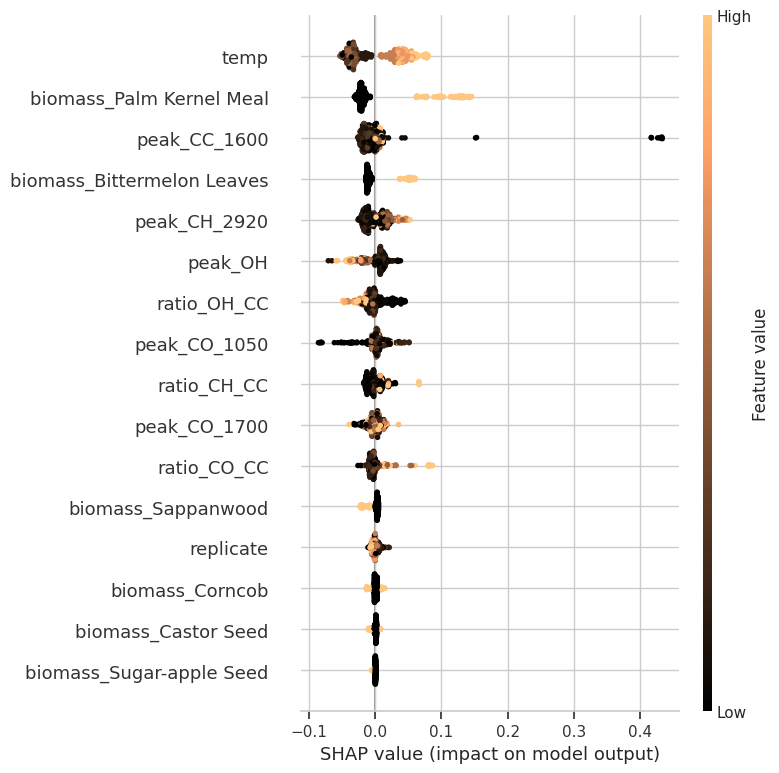

In [77]:
# ==========================================================
# SHAP Beeswarm Plot (Maple Theme Colormap)
# ==========================================================
plt.figure(figsize=(10, 10))
# Passing a custom warm maple colormap ('copper' / autumn) for beeswarm interaction
shap.summary_plot(shap_values, X_transformed_df, show=False, cmap=plt.get_cmap("copper"))
plt.tight_layout()
plt.show()

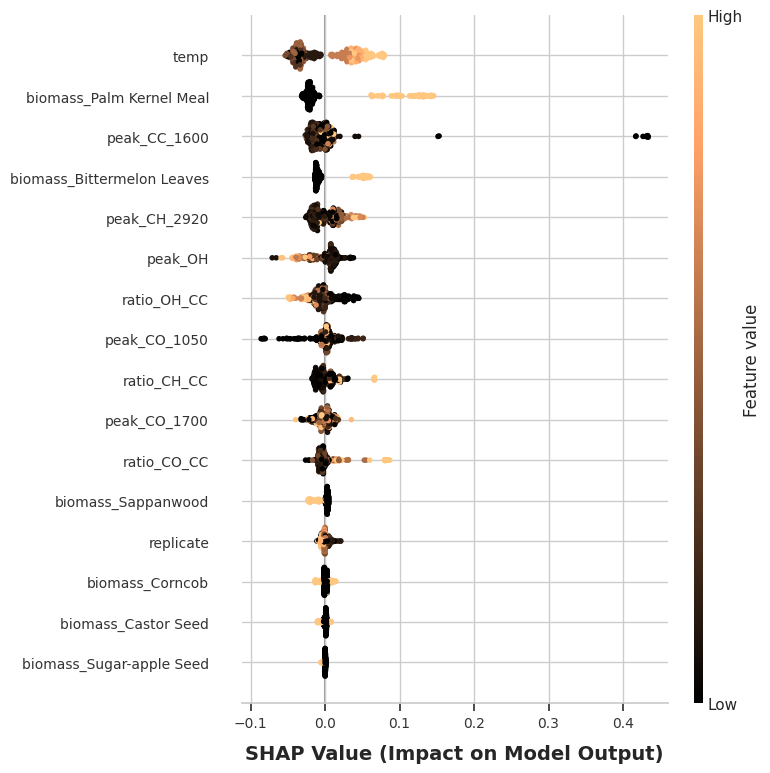

In [81]:
import matplotlib.pyplot as plt
import shap

# Mengatur ukuran figure agar lebih lega dan proporsional
plt.figure(figsize=(12, 4))

# Menggambar SHAP Beeswarm plot dengan colormap bertema musim gugur/maple ('copper')
# Kita set show=False agar bisa memodifikasi komponen teks di dalam plot
shap.summary_plot(
    shap_values,
    X_transformed_df,
    show=False,
    cmap=plt.get_cmap("copper")
)

# Mengatur ukuran font untuk judul, label sumbu, dan ticks agar lebih terbaca
plt.xlabel("SHAP Value (Impact on Model Output)", fontsize=14, fontweight='bold', labelpad=10)

# Mengubah ukuran font pada label ticks sumbu X dan Y secara dinamis
plt.tick_params(axis='x', labelsize=10)
plt.tick_params(axis='y', labelsize=10)

plt.tight_layout()
plt.show()